# Elo: nível de atenção por subprefeitura em dias de chuva

**Global Solution 2026.2 · CitizenTech · Inteligência Artificial & Machine Learning**

Este notebook percorre o ciclo completo de Machine Learning pedido no enunciado: problema, dados reais e públicos, preparação, divisão treino/teste, treino com diferentes hiperparâmetros, avaliação em treino e teste, discussão de overfitting e leitura do resultado para o cidadão.

| Etapa do enunciado | Onde está neste notebook |
|---|---|
| 1. Problema e dados reais | Seções 1 e 2 |
| 2. Modelo e preparação | Seções 3 a 7 |
| 3. Treino e avaliação (mais de 10 combinações, 3 hiperparâmetros, validação cruzada só no treino) | Seção 8 |
| 4. Resultados em treino e teste, overfitting e conclusão para o cidadão | Seções 9 a 13 |

**Nenhum dado deste notebook é simulado.** Todas as linhas vêm de fontes públicas (CGE-SP, INMET, Open-Meteo e GeoSampa) e estão documentadas em `dados/README.md`.

In [1]:
%matplotlib inline
import json
import platform
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, ScalarFormatter
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# Semente fixa: rodar de novo dá o mesmo resultado.
SEED = 42
np.random.seed(SEED)

# Pastas do projeto (caminhos relativos à pasta ml/).
BASE = Path.cwd() if (Path.cwd() / "dados").exists() else Path.cwd() / "ml"
BRUTOS = BASE / "dados" / "brutos"
FIGURAS = BASE / "figuras"
RESULTADOS = BASE / "resultados"
FIGURAS.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)

# Período estudado e corte do teste. O teste é 2025 inteiro: o futuro em relação ao treino.
INICIO = pd.Timestamp("2023-01-01")
FIM = pd.Timestamp("2025-12-31")
INICIO_TESTE = pd.Timestamp("2025-01-01")

# Estilo dos gráficos: paleta validada para daltonismo. Treino = azul, teste = laranja, validação = verde-água.
AZUL, LARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
CINZA = "#898781"
mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "axes.titlecolor": "#0b0b0b", "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9, "legend.frameon": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
})

def salvar(fig, nome):
    # Usa vírgula decimal nos eixos numéricos e salva a figura em figuras/ para o relatório usar o mesmo gráfico do notebook.
    for ax in fig.axes:
        for eixo in (ax.xaxis, ax.yaxis):
            if isinstance(eixo.get_major_formatter(), ScalarFormatter):
                eixo.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
    fig.savefig(FIGURAS / f"{nome}.png")
    plt.show()

def virgula(texto):
    # Troca o ponto decimal por vírgula nos textos gerados em português, sem mexer em números de seção.
    return re.sub(r"(?<!seção \d)(?<!seção \d\d)(?<=\d)\.(?=\d)", ",", texto)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

Python 3.11.9 | numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0 | xgboost 3.2.0


## 1. O problema e a pergunta de Machine Learning

**Problema da CitizenTech (Elo).** Quando a chuva aperta, o alerta oficial avisa a cidade, mas quem coordena o bairro não sabe quais ruas estão bem, quais precisam de ajuda e quais ficaram em silêncio. No Elo, a liderança de cada rua responde em um toque, e o coordenador do bairro vê quem falta.

**O papel do ML no Elo.** O modelo ajuda o coordenador a decidir **quando acionar a chamada**. Ele parte de uma hipótese que ainda precisa ser confirmada em conversa com uma liderança: abrir a chamada em todo dia de chuva cansaria os voluntários, e abrir tarde demais perderia o momento.

**Por que o modelo responde "quando" e não "quais ruas".** A pergunta central do Elo é quais ruas ficaram em silêncio, mas esse dado real ainda não existe: as respostas do app são simuladas, e o enunciado de ML não aceita dados simulados. Por isso, o ML responde à pergunta anterior, que tem dado real e público: em que dias vale abrir a chamada.

**Pergunta de ML.** *Para cada subprefeitura de São Paulo e para cada dia, qual é a probabilidade de o CGE registrar ao menos um ponto de alagamento naquela subprefeitura naquele dia?* A probabilidade é convertida em um **nível de atenção** (baixo, médio ou alto).

| Item | Definição |
|---|---|
| Tipo de problema | Classificação binária supervisionada, com saída em probabilidade |
| Unidade de análise | Uma linha por par subprefeitura + dia (32 subprefeituras × 1.096 dias) |
| Variável-alvo `alagou` | 1 se o CGE registrou ao menos um ponto de alagamento na subprefeitura no dia; 0 caso contrário |
| Momento da decisão | Manhã do dia, antes da chuva, com a previsão emitida até a noite anterior. O modelo não usa a chuva que ainda vai cair |
| Quem usa e onde vê | O coordenador do bairro ou voluntário de NUPDEC. O nível foi pensado para uma linha da tela Bairro ("Nível de atenção hoje"), ainda não integrada ao app |
| O que o coordenador faz | Baixo: nada muda. Médio: avisa as lideranças e deixa a chamada pronta. Alto: abre a chamada |
| O que o modelo **não** faz | Não emite alerta, não aponta qual rua vai alagar e não diz se há perigo. O aviso oficial continua sendo o do INMET e da Defesa Civil |

## 2. Dados reais e públicos

| Fonte | O que traz | Link | Período | Uso no projeto |
|---|---|---|---|---|
| **CGE-SP** (Centro de Gerenciamento de Emergências Climáticas, Prefeitura de SP) | Pontos de alagamento por dia e subprefeitura | https://www.cgesp.org/v3/alagamentos.jsp | 01/01/2023 a 31/12/2025 | Variável-alvo |
| **Open-Meteo Previous Runs** (modelo JMA GSM) | Chuva **prevista** 24 horas antes, por hora, no centro de cada subprefeitura | https://open-meteo.com/en/docs/previous-runs-api | 01/01/2023 a 31/12/2025 | Variável central do modelo |
| **INMET** (estações automáticas A701 Mirante e A771 Interlagos) | Chuva **observada** por hora | https://portal.inmet.gov.br/dadoshistoricos | 01/01/2023 a 31/12/2025 | Conferir as outras fontes, candidatas a variável e cenário com chuva medida |
| **Open-Meteo Historical** (reanálise) | Chuva e umidade do solo por hora no centro de cada subprefeitura | https://open-meteo.com/en/docs/historical-weather-api | 01/01/2023 a 31/12/2025 | Candidatas a variável e cenário com chuva medida |
| **GeoSampa** (Prefeitura de SP) | Limites, área e região das 32 subprefeituras | https://geosampa.prefeitura.sp.gov.br | Consulta em nov/2026 | Lista das subprefeituras, centroides e atributos candidatos |
| **Open-Meteo Elevation** | Elevação no centroide de cada subprefeitura | https://open-meteo.com/en/docs/elevation-api | Consulta em nov/2026 | Atributo candidato |

**Por que o modelo JMA.** A Previous Runs API guarda a previsão emitida na véspera, que é o dado que existe de verdade na hora de decidir. O JMA GSM é o único modelo da API com essa previsão desde 2023, então a mesma fonte serve ao treino e ao teste. Os outros modelos começam em 2024 ou depois. O custo é a resolução: as 32 subprefeituras caem em só 3 pontos de grade, e a chuva vem em blocos de 6 horas, com o mesmo valor em todas as horas do bloco.

Os scripts que baixam cada fonte estão em `coleta/`. O dicionário completo das colunas e o tratamento feito em cada arquivo estão em `dados/README.md`.

In [2]:
# 2.1 Carga dos arquivos brutos
cge_bruto = pd.read_csv(BRUTOS / "cge_alagamentos_2023_2025.csv", parse_dates=["data"], keep_default_na=False)
datas_cge = pd.read_csv(BRUTOS / "cge_datas_coletadas.csv", parse_dates=["data"])
inmet_bruto = pd.read_csv(BRUTOS / "inmet_horario_sp_2023_2025.csv", parse_dates=["ts_utc", "ts_local"])
subs = pd.read_csv(BRUTOS / "subprefeituras_geosampa.csv")
mapa_nomes = pd.read_csv(BRUTOS / "mapa_nomes_cge_geosampa.csv")
om_bruto = pd.read_csv(BRUTOS / "openmeteo_horario_subprefeituras_2023_2025.csv.gz", parse_dates=["ts_local"])
prev_bruto = pd.read_csv(BRUTOS / "openmeteo_previsao_d1_jma_horario_2023_2025.csv.gz", parse_dates=["ts_local"])

resumo_arquivos = pd.DataFrame([
    ("CGE, pontos de alagamento", len(cge_bruto), cge_bruto["data"].min().date(), cge_bruto["data"].max().date()),
    ("CGE, situação de cada data", len(datas_cge), datas_cge["data"].min().date(), datas_cge["data"].max().date()),
    ("INMET, horário (2 estações)", len(inmet_bruto), inmet_bruto["ts_local"].min().date(), inmet_bruto["ts_local"].max().date()),
    ("Open-Meteo, reanálise horária (32 subprefeituras)", len(om_bruto), om_bruto["ts_local"].min().date(), om_bruto["ts_local"].max().date()),
    ("Open-Meteo, previsão da véspera JMA (32 subprefeituras)", len(prev_bruto), prev_bruto["ts_local"].min().date(), prev_bruto["ts_local"].max().date()),
    ("GeoSampa, subprefeituras", len(subs), "-", "-"),
], columns=["arquivo", "linhas", "de", "até"])
display(resumo_arquivos)

,arquivo,linhas,de,até
0,"CGE, pontos de alagamento",2159,2023-01-01,2025-12-31
1,"CGE, situação de cada data",1096,2023-01-01,2025-12-31
2,"INMET, horário (2 estações)",52608,2023-01-01,2025-12-31
3,"Open-Meteo, reanálise horária (32 subprefeituras)",841728,2023-01-01,2025-12-31
4,"Open-Meteo, previsão da véspera JMA (32 subpre...",841728,2023-01-01,2025-12-31
5,"GeoSampa, subprefeituras",32,-,-


In [3]:
# 2.2 Toda data do período foi coletada?
periodo = pd.date_range(INICIO, FIM, freq="D")
faltam = sorted(set(periodo) - set(datas_cge["data"]))
assert len(faltam) == 0, f"Datas sem coleta: {faltam[:10]}"
assert datas_cge["data"].is_unique
print("Dias no período:", len(periodo))
print(datas_cge["situacao"].value_counts().to_string())
print()
print("Regra usada: 'sem_registro' é a mensagem oficial do CGE 'Não há registros de alagamentos para essa data'.")
print("Falha de rede nunca vira 'sem_registro': o coletor repete a requisição e interrompe se não conseguir.")

Dias no período: 1096
situacao
sem_registro    863
com_registro    233

Regra usada: 'sem_registro' é a mensagem oficial do CGE 'Não há registros de alagamentos para essa data'.
Falha de rede nunca vira 'sem_registro': o coletor repete a requisição e interrompe se não conseguir.


## 3. Preparação dos dados

Cada fonte passa por limpeza própria antes de virar variável. Toda decisão fica documentada abaixo, e os pontos críticos são verificados com `assert`, para o notebook parar se algo sair do esperado.

In [4]:
# 3.1 CGE: padronização, duplicatas e nomes de subprefeitura
cge = cge_bruto.copy()
for coluna in ["zona", "subprefeitura_cge", "local", "sentido", "referencia", "hora_inicio", "hora_fim"]:
    cge[coluna] = cge[coluna].astype(str).str.strip()

# Duplicata exata = mesma data, subprefeitura, horário e endereço. Não representa um novo alagamento.
chave = ["data", "subprefeitura_cge", "hora_inicio", "hora_fim", "local", "sentido", "referencia"]
duplicadas = int(cge.duplicated(subset=chave).sum())
cge = cge.drop_duplicates(subset=chave).copy()

# Cada nome usado pelo CGE precisa corresponder a exatamente uma das 32 subprefeituras do GeoSampa.
cge = cge.merge(mapa_nomes, on="subprefeitura_cge", how="left", validate="many_to_one")
assert cge["subprefeitura"].notna().all(), "Existe subprefeitura do CGE sem correspondência no GeoSampa"
assert set(cge["subprefeitura"]) <= set(subs["subprefeitura"])
assert cge["data"].between(INICIO, FIM).all()

# Horários: o CGE informa início e fim do ponto. Evento que passa da meia-noite tem fim menor que início.
inicio_ts = pd.to_datetime(cge["data"].dt.strftime("%Y-%m-%d") + " " + cge["hora_inicio"], errors="coerce", format="%Y-%m-%d %H:%M")
fim_ts = pd.to_datetime(cge["data"].dt.strftime("%Y-%m-%d") + " " + cge["hora_fim"], errors="coerce", format="%Y-%m-%d %H:%M")
sem_hora = int(inicio_ts.isna().sum())
fim_ts = fim_ts.where(~(fim_ts < inicio_ts), fim_ts + pd.Timedelta(days=1))
cge["duracao_min"] = (fim_ts - inicio_ts).dt.total_seconds() / 60

# O endereço do ponto indica se é avenida. Importante para discutir o viés do rótulo.
cge["em_avenida"] = cge["local"].str.upper().str.match(r"^(AV|AVENIDA)\b")

# Campos usados para testar alvos mais próximos do uso do Elo (seção 12).
cge["transitavel"] = pd.to_numeric(cge["transitavel"])
cge["longo"] = cge["duracao_min"] >= 60
cge["intransitavel"] = cge["transitavel"] == 0
cge["fora_avenida"] = ~cge["em_avenida"]
cge["depois_8h"] = inicio_ts.dt.hour >= 8

# Registros com asterisco no endereço: o CGE não explica o símbolo. São mantidos, pois são registros oficiais publicados.
com_asterisco = cge[cge["local"].str.startswith("*")]
print(f"Registros com '*' no endereço: {len(com_asterisco)} ({com_asterisco['subprefeitura_cge'].nunique()} subprefeitura, "
      f"{com_asterisco['data'].min():%d/%m/%Y} a {com_asterisco['data'].max():%d/%m/%Y})")

registros_ano = cge.groupby(cge["data"].dt.year).size()
dias_ano = cge.groupby(cge["data"].dt.year)["data"].nunique()
print(f"Registros brutos: {len(cge_bruto):,} | duplicatas exatas removidas: {duplicadas:,} | registros finais: {len(cge):,}".replace(",", "."))
print(f"Registros sem horário de início válido: {sem_hora} (mantidos, pois a data é válida; o horário não entra no modelo)")
pct_curtos = (cge["duracao_min"] < 60).mean()
print(f"Duração mediana de um ponto: {cge['duracao_min'].median():.0f} min | pontos com menos de 1 hora: {pct_curtos:.0%}")
pct_antes_8h = (inicio_ts.dt.hour < 8).mean()
print(f"Pontos que começam antes das 8h: {pct_antes_8h:.0%}. Eles ficam no alvo, embora parte aconteça antes da decisão da manhã.")
display(pd.DataFrame({"registros": registros_ano, "dias_com_alagamento": dias_ano}).rename_axis("ano"))

Registros com '*' no endereço: 27 (1 subprefeitura, 02/02/2025 a 04/02/2025)
Registros brutos: 2.159 | duplicatas exatas removidas: 4 | registros finais: 2.155
Registros sem horário de início válido: 0 (mantidos, pois a data é válida; o horário não entra no modelo)
Duração mediana de um ponto: 82 min | pontos com menos de 1 hora: 39%
Pontos que começam antes das 8h: 18%. Eles ficam no alvo, embora parte aconteça antes da decisão da manhã.


,registros,dias_com_alagamento
ano,,
2023,822,86
2024,701,68
2025,632,79


In [5]:
# 3.2 Comparação com os números que o escopo do grupo cita (base antiga do grupo não foi fornecida).
por_sub = cge.groupby("subprefeitura").size()
tabela_escopo = pd.DataFrame([
    ("Pontos de alagamento", "2.137", f"{len(cge):,}".replace(",", ".")),
    ("Dias com linha na base (2023-2025)", "1.055", f"{len(periodo):,}".replace(",", ".")),
    ("Dias com alagamento por ano", "68 a 82", f"{dias_ano.min()} a {dias_ano.max()}"),
    ("Pontos na Sé", "335", str(int(por_sub.get("SE", 0)))),
    ("Pontos em Cidade Tiradentes", "5", str(int(por_sub.get("CIDADE TIRADENTES", 0)))),
    ("% dos pontos em avenidas", "53%", f"{cge['em_avenida'].mean() * 100:.0f}%"),
], columns=["indicador", "escopo do grupo", "base reconstruída"])
display(tabela_escopo)
print("A base citada no escopo não foi fornecida, e o escopo não explica os 1.055 dias. Aqui entram todos os dias do período.")

,indicador,escopo do grupo,base reconstruída
0,Pontos de alagamento,2.137,2.155
1,Dias com linha na base (2023-2025),1.055,1.096
2,Dias com alagamento por ano,68 a 82,68 a 86
3,Pontos na Sé,335,339
4,Pontos em Cidade Tiradentes,5,5
5,% dos pontos em avenidas,53%,54%


A base citada no escopo não foi fornecida, e o escopo não explica os 1.055 dias. Aqui entram todos os dias do período.


In [6]:
# 3.3 INMET: chuva observada por hora -> chuva por dia local
inmet = inmet_bruto.copy()
# O INMET publica em UTC. O dia do CGE é o dia local (UTC-3), então o dia é definido pelo horário local.
inmet["data"] = inmet["ts_local"].dt.normalize()
inmet = inmet[inmet["data"].between(INICIO, FIM)]

por_dia = inmet.groupby(["estacao", "data"])["chuva_mm"].agg(
    chuva="sum", max1h="max", horas_validas="count").reset_index()
# Um dia com muitas horas sem medição subestimaria a chuva. Com menos de 20 horas válidas, o dia fica como faltante.
por_dia.loc[por_dia["horas_validas"] < 20, ["chuva", "max1h"]] = np.nan

faltantes = por_dia.assign(ano=por_dia["data"].dt.year).groupby(["estacao", "ano"])["chuva"].apply(lambda s: s.isna().mean() * 100)
print("% de dias sem chuva utilizável por estação e ano (fica como NaN; o Pipeline imputa quando a variável é usada):")
display(faltantes.unstack("ano").round(1))

# Maior sequência de dias sem dado utilizável em cada estação (os dias continuam na base, como NaN).
for estacao, grupo_est in por_dia.groupby("estacao"):
    falta = grupo_est.loc[grupo_est["chuva"].isna(), "data"].sort_values()
    if len(falta):
        blocos = (falta.diff() != pd.Timedelta(days=1)).cumsum()
        maior = falta.groupby(blocos).agg(["min", "max", "size"]).sort_values("size").iloc[-1]
        print(f"{estacao}: {len(falta)} dias sem dado; maior sequência de {maior['size']} dias, de {maior['min']:%d/%m/%Y} a {maior['max']:%d/%m/%Y}")

inmet_dia = por_dia.pivot(index="data", columns="estacao", values=["chuva", "max1h"])
inmet_dia.columns = [f"inmet_{var}_{estacao}" for var, estacao in inmet_dia.columns]
inmet_dia = inmet_dia.reindex(periodo).rename_axis("data")

% de dias sem chuva utilizável por estação e ano (fica como NaN; o Pipeline imputa quando a variável é usada):


ano,2023,2024,2025
estacao,,,
A701,9.6,0.3,0.3
A771,4.4,0.0,0.3


A701: 37 dias sem dado; maior sequência de 20 dias, de 24/08/2023 a 12/09/2023
A771: 17 dias sem dado; maior sequência de 6 dias, de 06/06/2023 a 11/06/2023


In [7]:
# 3.4 Open-Meteo: chuva e umidade do solo por hora -> variáveis por subprefeitura e dia
om = om_bruto.copy()
om["data"] = om["ts_local"].dt.normalize()
om = om[om["data"].between(INICIO, FIM)]

# Na Open-Meteo, cada hora traz a chuva da hora anterior, então o dia D vai das 23h de D-1 às 23h de D. A convenção foi mantida.
om_dia = om.groupby(["subprefeitura", "data"]).agg(
    om_chuva=("chuva_mm", "sum"),
    om_max1h=("chuva_mm", "max"),
    om_horas_chuva=("chuva_mm", lambda s: int((s >= 0.1).sum())),
).reset_index()

# Umidade do solo às 00h: estimada para o início do dia, portanto sem vazamento da chuva do próprio dia.
solo_0h = (om[om["ts_local"].dt.hour == 0][["subprefeitura", "data", "umidade_solo_0_7cm"]]
           .rename(columns={"umidade_solo_0_7cm": "om_solo_0h"}))
om_dia = om_dia.merge(solo_0h, on=["subprefeitura", "data"], how="left", validate="one_to_one")

assert om_dia.groupby("subprefeitura")["data"].nunique().eq(len(periodo)).all()
print("Pontos de grade distintos da Open-Meteo:", om.groupby(["grid_lat", "grid_lon"]).ngroups,
      "para", om["subprefeitura"].nunique(), "subprefeituras")
print("Linhas da tabela diária Open-Meteo:", len(om_dia))

Pontos de grade distintos da Open-Meteo: 19 para 32 subprefeituras
Linhas da tabela diária Open-Meteo: 35072


In [8]:
# 3.5 Previsão da véspera (JMA GSM): a chuva que era esperada para cada dia e subprefeitura
prev = prev_bruto.copy()
prev["data"] = prev["ts_local"].dt.normalize()
prev = prev[prev["data"].between(INICIO, FIM)]

prev_dia = prev.groupby(["subprefeitura", "data"]).agg(
    prev_chuva=("chuva_prevista_d1_mm", "sum"),
    prev_max_bloco=("chuva_prevista_d1_mm", "max"),
    prev_horas=("chuva_prevista_d1_mm", lambda s: int((s >= 0.1).sum())),
    horas_validas=("chuva_prevista_d1_mm", "count"),
).reset_index()
prev_dia.loc[prev_dia["horas_validas"] < 20, ["prev_chuva", "prev_max_bloco", "prev_horas"]] = np.nan
prev_dia = prev_dia.drop(columns="horas_validas")

assert prev_dia.groupby("subprefeitura")["data"].nunique().eq(len(periodo)).all()
# A JMA publica a chuva em blocos de 6 horas. Por isso, prev_max_bloco é a intensidade (mm/h) do bloco mais chuvoso, e não um máximo horário.
exemplo_prev = prev[prev["subprefeitura"] == "SE"].sort_values("ts_local")
horas_exemplo = ((exemplo_prev["ts_local"] - exemplo_prev["ts_local"].iloc[0]).dt.total_seconds() / 3600).astype(int)
blocos_constantes = max(exemplo_prev.groupby((horas_exemplo + d) // 6)["chuva_prevista_d1_mm"].nunique().eq(1).mean() for d in range(6))
print(f"Blocos de 6 horas com um único valor de chuva: {blocos_constantes:.1%}")
n_grade_prev = prev.groupby(["grid_lat", "grid_lon"]).ngroups
print(f"Pontos de grade da previsão: {n_grade_prev} para {prev['subprefeitura'].nunique()} subprefeituras | "
      f"dias com previsão completa: {prev_dia['prev_chuva'].notna().mean():.1%}")

Blocos de 6 horas com um único valor de chuva: 100.0%
Pontos de grade da previsão: 3 para 32 subprefeituras | dias com previsão completa: 100.0%


In [9]:
# 3.6 As fontes de chuva são coerentes com a medição do INMET? (somente treino)
# Cada estação é comparada com a subprefeitura onde está: A701 em Santana-Tucuruvi e A771 em Capela do Socorro.
pares_estacao = [("SANTANA-TUCURUVI", "A701"), ("CAPELA DO SOCORRO", "A771")]
linhas = []
for sub_estacao, estacao in pares_estacao:
    junto = (om_dia[om_dia["subprefeitura"] == sub_estacao].set_index("data")[["om_chuva"]]
             .join(prev_dia[prev_dia["subprefeitura"] == sub_estacao].set_index("data")["prev_chuva"])
             .join(inmet_dia[f"inmet_chuva_{estacao}"]).dropna())
    junto = junto[junto.index < INICIO_TESTE]  # a decisão sobre as fontes não olha o ano de teste
    medido = junto[f"inmet_chuva_{estacao}"]
    for rotulo, serie in [("Reanálise Open-Meteo", junto["om_chuva"]), ("Previsão da véspera (JMA)", junto["prev_chuva"])]:
        forte_fonte, forte_medido = serie >= 20, medido >= 20  # "choveu forte" = 20 mm ou mais no dia
        linhas.append({"subprefeitura e estação": f"{sub_estacao} / {estacao}", "fonte": rotulo,
                       "correlação com o INMET": serie.corr(medido),
                       "total da fonte (mm)": serie.sum(), "total medido (mm)": medido.sum(),
                       "dias de chuva forte em comum (%)": 100 * (forte_fonte & forte_medido).sum() / (forte_fonte | forte_medido).sum()})
coerencia = pd.DataFrame(linhas)
display(coerencia.round(2))

,subprefeitura e estação,fonte,correlação com o INMET,total da fonte (mm),total medido (mm),dias de chuva forte em comum (%)
0,SANTANA-TUCURUVI / A701,Reanálise Open-Meteo,0.68,2496.5,3203.2,26.98
1,SANTANA-TUCURUVI / A701,Previsão da véspera (JMA),0.55,2111.6,3203.2,19.67
2,CAPELA DO SOCORRO / A771,Reanálise Open-Meteo,0.55,2460.1,3068.8,16.67
3,CAPELA DO SOCORRO / A771,Previsão da véspera (JMA),0.33,3398.6,3068.8,12.50


**Decisão sobre as fontes de chuva.** A tabela mostra o limite de cada fonte nos dois pares possíveis de estação e subprefeitura. A reanálise da Open-Meteo não é medição e subestima a chuva. A previsão da véspera concorda menos ainda com o INMET e erra boa parte dos dias de chuva forte. Mesmo assim, ela é a única das três que existe na manhã do dia. Por isso, o modelo principal usa a previsão, e a chuva medida no próprio dia só aparece no cenário comparativo da seção 11.

In [10]:
# 3.7 Base final: 1 linha por subprefeitura e dia, inclusive os dias SEM alagamento
base = pd.MultiIndex.from_product([periodo, subs["subprefeitura"]], names=["data", "subprefeitura"]).to_frame(index=False)

# Rótulo: se não existe registro do CGE, o valor é 0. Essa é a definição do alvo, e a limitação dela é discutida na seção 12.
contagem = cge.groupby(["data", "subprefeitura"]).agg(
    n_pontos=("local", "size"), alagou_longo=("longo", "max"),
    alagou_intransitavel=("intransitavel", "max"), alagou_fora_avenida=("fora_avenida", "max"),
    alagou_depois_8h=("depois_8h", "max")).reset_index()
base = base.merge(contagem, on=["data", "subprefeitura"], how="left")
base["n_pontos"] = base["n_pontos"].fillna(0).astype(int)
for coluna in ["alagou_longo", "alagou_intransitavel", "alagou_fora_avenida", "alagou_depois_8h"]:
    base[coluna] = base[coluna].fillna(False).astype(bool).astype(int)
base["alagou"] = (base["n_pontos"] > 0).astype(int)
base = base.sort_values(["subprefeitura", "data"]).reset_index(drop=True)

# Junta INMET, reanálise, previsão da véspera e atributos da subprefeitura.
base = base.merge(inmet_dia.reset_index(), on="data", how="left", validate="many_to_one")
base = base.merge(om_dia, on=["subprefeitura", "data"], how="left", validate="one_to_one")
base = base.merge(prev_dia, on=["subprefeitura", "data"], how="left", validate="one_to_one")
base = base.merge(subs[["subprefeitura", "nome_exibicao", "regiao5", "area_km2", "elevacao_m"]],
                  on="subprefeitura", how="left", validate="many_to_one")

assert len(base) == len(periodo) * 32
assert not base.duplicated(["data", "subprefeitura"]).any()
print("Linhas da base final:", len(base), "| colunas:", base.shape[1])
print(f"Prevalência de alagou = 1: {base['alagou'].mean():.2%} ({base['alagou'].sum()} de {len(base)} linhas)")

Linhas da base final: 35072 | colunas: 23
Prevalência de alagou = 1: 3.15% (1104 de 35072 linhas)


In [11]:
# 3.8 Variáveis de contexto: sempre com informação de dias ANTERIORES ao dia previsto

def acumulado_anterior(serie, dias):
    # Soma da chuva nos 'dias' anteriores (D-1 até D-dias). O dia D nunca entra na conta.
    return serie.shift(1).rolling(dias, min_periods=dias).sum()

# Contexto por subprefeitura (Open-Meteo)
grupo = base.groupby("subprefeitura", group_keys=False)
for dias in (1, 3, 7, 14):
    base[f"om_acum_{dias}d"] = grupo["om_chuva"].transform(lambda s: acumulado_anterior(s, dias))

# Contexto medido pelo INMET (mesmo valor para toda a cidade naquele dia)
inmet_contexto = inmet_dia.copy()
for estacao in ("A701", "A771"):
    for dias in (1, 3, 7):
        inmet_contexto[f"inmet_acum_{dias}d_{estacao}"] = acumulado_anterior(inmet_contexto[f"inmet_chuva_{estacao}"], dias)
base = base.drop(columns=base.filter(like="inmet_acum_").columns)  # permite executar esta célula de novo sem duplicar colunas
base = base.merge(inmet_contexto.filter(like="acum").reset_index(), on="data", how="left", validate="many_to_one")

# Alagou ontem nesta subprefeitura? Esse dado existe de manhã, portanto pode ser usado.
base["alagou_ontem"] = base.groupby("subprefeitura")["alagou"].shift(1)
base["pontos_cidade_ontem"] = base["data"].map(cge.groupby("data").size().reindex(periodo, fill_value=0).shift(1))

# Calendário: captura a estação chuvosa (o verão) sem usar o ano.
base["mes"] = base["data"].dt.month
base["estacao_chuvosa"] = base["mes"].isin([10, 11, 12, 1, 2, 3]).astype(int)  # outubro a março
print("Colunas criadas. Os faltantes vêm do início da série (janela de acumulado incompleta) e das falhas das estações, e ficam como NaN:")
display(base[["om_acum_14d", "inmet_acum_7d_A701", "alagou_ontem"]].isna().mean().mul(100).round(2).rename("% faltante").to_frame())

Colunas criadas. Os faltantes vêm do início da série (janela de acumulado incompleta) e das falhas das estações, e ficam como NaN:


,% faltante
om_acum_14d,1.28
inmet_acum_7d_A701,10.77
alagou_ontem,0.09


In [12]:
# 3.9 Regras contra vazamento de dados (data leakage)
# 1) Nenhuma variável usa o CGE do próprio dia: o único uso do CGE como entrada é com atraso de 1 dia.
# 2) Os acumulados param em D-1, e a umidade do solo é a das 00h do dia D.
# 3) A previsão do dia D é a emitida 24 horas antes, então já existia antes do dia começar.
# 4) As conferências abaixo valem para todas as linhas da base, e não só para uma amostra.
conf = base.sort_values(["subprefeitura", "data"])
grupo_conf = conf.groupby("subprefeitura")

for dias in (1, 3, 7, 14):
    # Soma explícita de D-1 até D-dias, feita de forma independente da função usada acima.
    soma_anteriores = sum(grupo_conf["om_chuva"].shift(k) for k in range(1, dias + 1))
    assert np.allclose(conf[f"om_acum_{dias}d"], soma_anteriores, equal_nan=True), f"om_acum_{dias}d deveria somar só dias anteriores"

for estacao in ("A701", "A771"):
    for dias in (1, 3, 7):
        soma_anteriores = sum(inmet_dia[f"inmet_chuva_{estacao}"].shift(k) for k in range(1, dias + 1))
        assert np.allclose(inmet_contexto[f"inmet_acum_{dias}d_{estacao}"], soma_anteriores, equal_nan=True), f"inmet_acum_{dias}d_{estacao} deveria somar só dias anteriores"

assert conf["alagou_ontem"].fillna(-1).eq(grupo_conf["alagou"].shift(1).fillna(-1)).all(), "alagou_ontem deveria repetir o alvo de D-1"
assert grupo_conf["alagou_ontem"].head(1).isna().all(), "alagou_ontem do primeiro dia deveria ser faltante"
pontos_por_dia = cge.groupby("data").size().reindex(periodo, fill_value=0)
assert conf["pontos_cidade_ontem"].fillna(-1).eq(conf["data"].map(pontos_por_dia.shift(1)).fillna(-1)).all(), "pontos_cidade_ontem deveria ser a contagem de D-1"
assert conf["prev_chuva"].notna().all(), "a previsão deveria cobrir todas as linhas"
assert conf["prev_chuva"].corr(conf["om_chuva"]) < 0.9, "a previsão não pode ser uma cópia da chuva observada"
print("Conferências de vazamento em toda a base: OK")

Conferências de vazamento em toda a base: OK


## 4. Análise exploratória

A análise exploratória responde três perguntas antes de treinar: **quando** acontece o alagamento, **quanto** a chuva explica e **onde** o registro se concentra. Ela usa só a base de treino (2023 e 2024), para que o ano de teste não influencie nenhuma decisão.

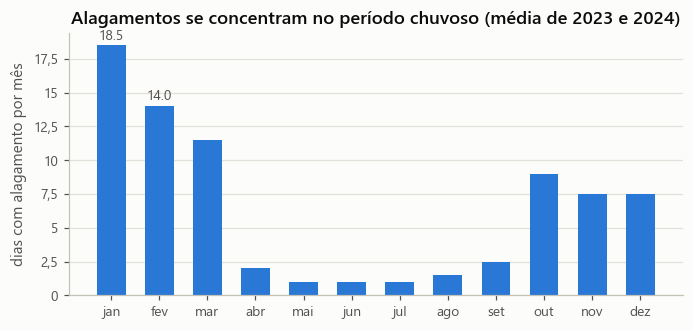

In [13]:
# 4.1 Quando acontece? (somente treino)
eda = base[base["data"] < INICIO_TESTE]
dias_por_mes = (eda[eda["alagou"] == 1].groupby("mes")["data"].nunique() / 2).reindex(range(1, 13), fill_value=0)

fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.bar(dias_por_mes.index, dias_por_mes.values, width=0.6, color=AZUL)
ax.set_xticks(range(1, 13), ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
ax.set_ylabel("dias com alagamento por mês")
ax.set_title("Alagamentos se concentram no período chuvoso (média de 2023 e 2024)")
ax.xaxis.grid(False)
for mes, valor in dias_por_mes.items():
    if valor >= dias_por_mes.nlargest(2).min():
        ax.annotate(f"{valor:.1f}", (mes, valor), ha="center", va="bottom", fontsize=9, color="#52514e", xytext=(0, 2), textcoords="offset points")
salvar(fig, "eda_sazonalidade")

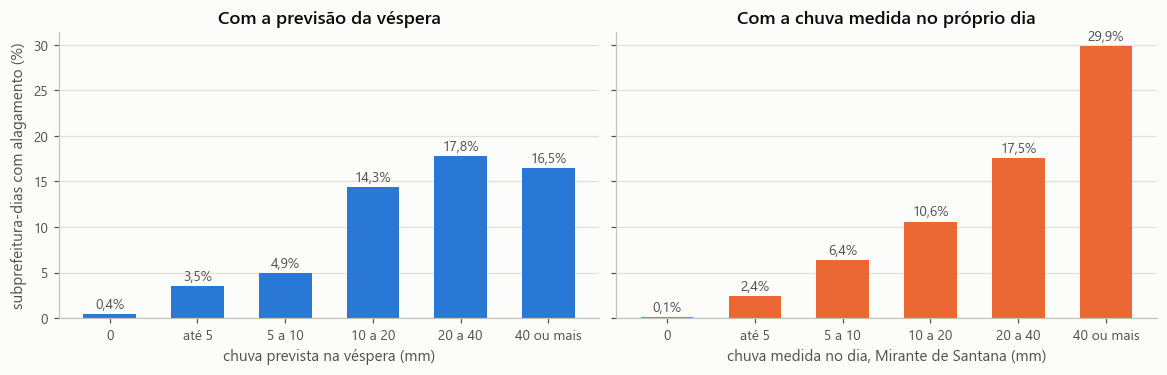

prev_chuva        inmet_chuva_A701       
                 taxa linhas             taxa linhas
faixa                                               
0                0.41  12170             0.14  13152
até 5            3.51   6894             2.44   4512
5 a 10           4.95   1779             6.40   1376
10 a 20         14.34   1918            10.60   1472
20 a 40         17.82    449            17.53   1152
40 ou mais      16.48    182            29.86    576

In [14]:
# 4.2 Quanto a chuva explica? (somente treino) A previsão e a medição lado a lado.
faixas = [0, 0.1, 5, 10, 20, 40, np.inf]
rotulos = ["0", "até 5", "5 a 10", "10 a 20", "20 a 40", "40 ou mais"]

fig, eixos = plt.subplots(1, 2, figsize=(10.5, 3.3), sharey=True, constrained_layout=True)
taxas_eda = {}
for eixo, coluna, rotulo_x, cor in [(eixos[0], "prev_chuva", "chuva prevista na véspera (mm)", AZUL),
                                    (eixos[1], "inmet_chuva_A701", "chuva medida no dia, Mirante de Santana (mm)", LARANJA)]:
    faixa = pd.cut(eda[coluna], faixas, right=False, labels=rotulos)
    taxa = eda.assign(faixa=faixa).dropna(subset=["faixa"]).groupby("faixa", observed=True)["alagou"].agg(taxa="mean", linhas="size")
    taxas_eda[coluna] = taxa
    barras = eixo.bar(taxa.index.astype(str), taxa["taxa"] * 100, width=0.6, color=cor)
    eixo.bar_label(barras, labels=[virgula(f"{v:.1f}%") for v in taxa["taxa"] * 100], padding=2, fontsize=9, color="#52514e")
    eixo.set_xlabel(rotulo_x)
    eixo.xaxis.grid(False)
eixos[0].set_ylabel("subprefeitura-dias com alagamento (%)")
eixos[0].set_title("Com a previsão da véspera")
eixos[1].set_title("Com a chuva medida no próprio dia")
salvar(fig, "eda_dose_resposta")
display(pd.concat({k: v.assign(taxa=lambda d: (d["taxa"] * 100).round(2)) for k, v in taxas_eda.items()}, axis=1))

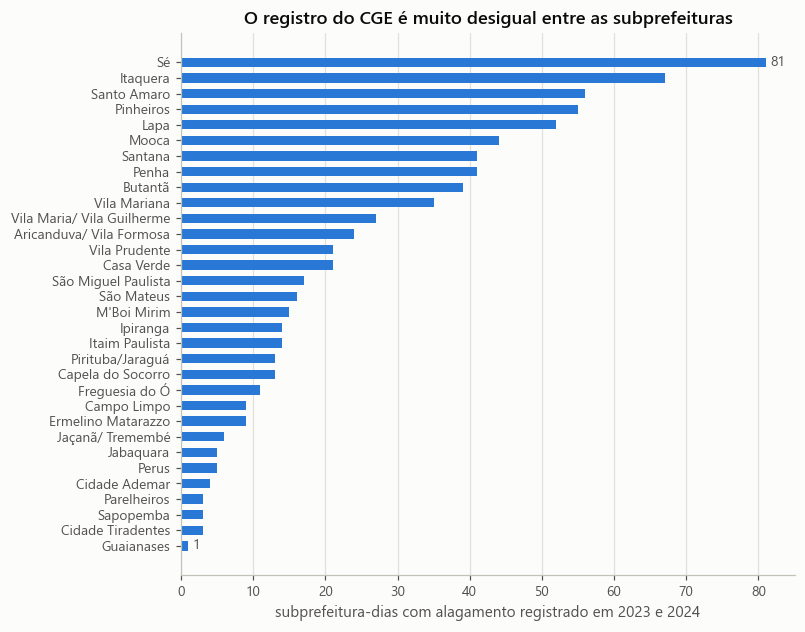

Maior contagem: Sé (81) | menor: Guaianases (1) | razão entre os extremos: 81 vezes | Sé em relação à mediana das demais: 5,4 vezes


In [15]:
# 4.3 Onde o registro se concentra? (somente treino)
por_sub_treino = eda.groupby("nome_exibicao")["alagou"].sum().sort_values()

fig, ax = plt.subplots(figsize=(7.2, 6.4))
ax.barh(por_sub_treino.index, por_sub_treino.values, height=0.6, color=AZUL)
ax.set_xlabel("subprefeitura-dias com alagamento registrado em 2023 e 2024")
ax.set_title("O registro do CGE é muito desigual entre as subprefeituras")
ax.yaxis.grid(False)
for nome, valor in list(por_sub_treino.items())[:1] + list(por_sub_treino.items())[-1:]:
    ax.annotate(str(int(valor)), (valor, nome), ha="left", va="center", fontsize=9, color="#52514e", xytext=(3, 0), textcoords="offset points")
salvar(fig, "eda_subprefeituras")
maior_sub, menor_sub = por_sub_treino.idxmax(), por_sub_treino.idxmin()
mediana_demais = por_sub_treino.drop(maior_sub).median()
print(virgula(f"Maior contagem: {maior_sub} ({por_sub_treino.max()}) | menor: {menor_sub} ({por_sub_treino.min()}) | "
              f"razão entre os extremos: {por_sub_treino.max() / max(por_sub_treino.min(), 1):.0f} vezes | "
              f"{maior_sub} em relação à mediana das demais: {por_sub_treino.max() / mediana_demais:.1f} vezes"))

**O que a exploração mostra e como isso muda o modelo**

- **Sazonalidade forte.** O mês é testado como variável (seção 7.3), e a validação não pode embaralhar datas: um dia de janeiro não prevê outro dia de janeiro do mesmo temporal.
- **A chuva explica muito, mas não tudo, e a previsão explica menos que a medição.** Nos dois painéis, a taxa de alagamento tende a subir com a chuva, mas nenhuma faixa garante o alagamento. Com a previsão, a subida é mais fraca. Por isso, o local e as condições anteriores entram como candidatas a variável.
- **O rótulo é desigual.** A contagem varia muito entre as subprefeituras: a razão entre os extremos é grande, mas a Sé fica em torno de 5 vezes a mediana das demais, e a desigualdade não é só centro contra periferia, pois Itaquera, na zona Leste, está entre as mais registradas. Em parte isso reflete o relevo e a impermeabilização; em parte reflete **onde o CGE observa e registra**, em vias monitoradas. Sem uma fonte independente, não dá para separar uma coisa da outra: a parte que vem de onde o CGE observa é uma hipótese. A seção 12 mede como o desempenho varia entre regiões.
- **Classes desbalanceadas.** Só uma pequena fração das linhas tem `alagou = 1`. Acurácia não serve como métrica: dizer "não alaga" sempre acertaria mais de 95% das linhas e seria inútil.

## 5. Escolha justificada do modelo

O problema tem dados tabulares, cerca de 3% de casos positivos e poucos anos de histórico. Os candidatos são os modelos supervisionados da lista do enunciado da disciplina que servem para esse tipo de dado.

| Modelo | Avaliação para este problema | Decisão |
|---|---|---|
| Regressão Logística | Simples e calibrável. Mostra diretamente o efeito da previsão e de cada subprefeitura | Candidata |
| Naive Bayes | Simples, mas supõe independência entre as medidas de chuva prevista | Candidata |
| Random Forest | Aprende interações sozinha, mas pede mais dados para estabilizar | Candidata |
| XGBoost | Aprende interações e tem controle explícito de complexidade | Candidata |
| MLP | Flexível, mas pouco explicável para o coordenador | Candidata |
| LSTM | Serve para sequências longas. Aqui, a decisão usa a previsão de um único dia e o local | Não testada |
| KMeans | É não supervisionado, e aqui existe rótulo real (CGE) | Não testado |

**A escolha é feita com evidência, nas seções 7.2 e 7.4.** As cinco candidatas passam pela mesma validação cruzada, e fica a mais simples que não seja pior do que a melhor. A comparação é feita duas vezes: antes de escolher as variáveis e depois, já com as variáveis finais.

O enunciado da disciplina lista a Regressão Logística. O slide 31 do documento geral da GS traz uma lista mais curta, sem ela. Este trabalho segue o enunciado da disciplina.

## 6. Divisão treino/teste, validação cruzada e regra de escolha

**Por que a divisão é temporal.** Se as linhas fossem sorteadas, o mesmo temporal apareceria no treino e no teste, em subprefeituras diferentes, e o modelo pareceria melhor do que é. Por isso:

- **Treino:** 2023 e 2024.
- **Teste:** 2025 inteiro, que é o futuro em relação ao treino e inclui um ciclo completo de estações.
- **Validação cruzada, só dentro do treino:** `TimeSeriesSplit` aplicado sobre os **dias**, com 5 dobras. Cada dobra treina em um período e valida no período seguinte, nunca o contrário, e todas as linhas de um mesmo dia ficam do mesmo lado da divisão.

Modelo, variáveis, hiperparâmetros e limiares são escolhidos só com o treino. O desempenho em 2025 é medido na seção 9. Antes dela, 2025 aparece apenas em contagens descritivas da base, como o total de alagamentos por ano.

**Regra de escolha, a mesma em todo o notebook.** Cada candidato é comparado com o melhor, dobra a dobra, pois as dobras variam muito entre si. Um candidato é equivalente ao melhor se a diferença média de PR-AUC for menor ou igual a um erro-padrão dessa diferença, ou menor que 0,005. Essa margem é uma convenção deste trabalho, cerca de 2% do PR-AUC das melhores combinações, e a seção 8.2 mostra o que mudaria sem ela. Entre os equivalentes, fica o mais simples.

**Transparência sobre o teste.** O ano de 2025 não é um teste perfeitamente cego. O teste rápido citado no escopo já usava 2025, e, durante o desenvolvimento, o notebook foi executado várias vezes, então as métricas de 2025 foram vistas antes desta versão. A versão anterior treinava com a chuva do próprio dia e foi refeita depois de uma correção que apontou que esse dado não existe na hora de decidir. Para limitar esse efeito, toda escolha nesta versão usa só a validação no treino, e o XGBoost, que era o modelo anterior, passou pela mesma comparação.

In [16]:
# 6.1 Divisão temporal
treino = base[base["data"] < INICIO_TESTE].reset_index(drop=True)
teste = base[base["data"] >= INICIO_TESTE].reset_index(drop=True)

assert treino["data"].max() < teste["data"].min()
assert not set(treino["data"]) & set(teste["data"])

def resumo_conjunto(df):
    return {
        "período": f"{df['data'].min():%d/%m/%Y} a {df['data'].max():%d/%m/%Y}",
        "linhas": len(df),
        "dias": df["data"].nunique(),
        "casos positivos": int(df["alagou"].sum()),
        "prevalência": f"{df['alagou'].mean():.2%}",
        "dias com algum alagamento": df.loc[df["alagou"] == 1, "data"].nunique(),
    }
display(pd.DataFrame({"treino": resumo_conjunto(treino), "teste": resumo_conjunto(teste)}))

,treino,teste
período,01/01/2023 a 31/12/2024,01/01/2025 a 31/12/2025
linhas,23392,11680
dias,731,365
casos positivos,765,339
prevalência,3.27%,2.90%
dias com algum alagamento,154,79


In [17]:
# 6.2 Dobras temporais da validação cruzada (por dia, sem embaralhar)
N_DOBRAS = 5

def dobras_temporais(datas, n_dobras=N_DOBRAS):
    # Ordena os dias, cria as dobras sobre os dias e devolve os índices das linhas.
    dias = np.sort(datas.unique())
    for idx_tr, idx_va in TimeSeriesSplit(n_splits=n_dobras).split(dias):
        yield (np.flatnonzero(datas.isin(dias[idx_tr])), np.flatnonzero(datas.isin(dias[idx_va])))

dobras = list(dobras_temporais(treino["data"]))
linhas = []
for i, (tr, va) in enumerate(dobras, start=1):
    linhas.append({"dobra": i,
                   "treino até": f"{treino['data'].iloc[tr].max():%d/%m/%Y}",
                   "validação": f"{treino['data'].iloc[va].min():%d/%m/%Y} a {treino['data'].iloc[va].max():%d/%m/%Y}",
                   "linhas de treino": len(tr), "linhas de validação": len(va),
                   "positivos na validação": int(treino["alagou"].iloc[va].sum())})
    assert treino["data"].iloc[tr].max() < treino["data"].iloc[va].min()  # treino sempre antes da validação
tabela_dobras = pd.DataFrame(linhas)
display(tabela_dobras)

,dobra,treino até,validação,linhas de treino,linhas de validação,positivos na validação
0,1,06/05/2023,07/05/2023 a 04/09/2023,4032,3872,17
1,2,04/09/2023,05/09/2023 a 03/01/2024,7904,3872,137
2,3,03/01/2024,04/01/2024 a 03/05/2024,11776,3872,197
3,4,03/05/2024,04/05/2024 a 01/09/2024,15648,3872,13
4,5,01/09/2024,02/09/2024 a 31/12/2024,19520,3872,138


In [18]:
# 6.3 Regra de escolha: compara cada candidato com o melhor, dobra a dobra
MARGEM_IRRELEVANTE = 0.005

def comparar_candidatos(pr_auc_por_dobra, nomes):
    # Uma linha por candidato e uma coluna por dobra.
    matriz = np.asarray(pr_auc_por_dobra)
    melhor = int(matriz.mean(axis=1).argmax())
    diferencas = matriz[melhor] - matriz
    media_dif = diferencas.mean(axis=1)
    erro_dif = diferencas.std(axis=1, ddof=1) / np.sqrt(matriz.shape[1])
    return pd.DataFrame({"PR-AUC (média das dobras)": matriz.mean(axis=1),
                         "diferença para o melhor": media_dif,
                         "erro-padrão da diferença": erro_dif,
                         "equivalente ao melhor": media_dif <= np.maximum(erro_dif, MARGEM_IRRELEVANTE)}, index=nomes)

## 7. Variáveis e modelo

| Grupo | Colunas | Existe na manhã do dia? |
|---|---|---|
| Previsão do dia (JMA) | `prev_chuva` (total do dia), `prev_max_bloco` (intensidade do bloco de 6 h mais chuvoso), `prev_horas` (horas com chuva, sempre em blocos) | Sim, foi emitida até a noite anterior |
| Local | `subprefeitura` | Sim |
| Atributos físicos do local | `area_km2`, `elevacao_m`, `regiao5` | Sim |
| Calendário | `mes`, `estacao_chuvosa` | Sim |
| Histórico recente do CGE | `alagou_ontem`, `pontos_cidade_ontem` | Sim. Na noite da véspera, o dia anterior ainda estaria incompleto |
| Chuva medida até a véspera | `inmet_acum_*` | Sim |
| Reanálise até a véspera e solo às 00h | `om_acum_*`, `om_solo_0h` | Com atraso: a reanálise pode chegar alguns dias depois |
| Chuva do próprio dia | `om_chuva`, `inmet_chuva_*`, `om_max1h`, `inmet_max1h_*` | **Não.** Não entra no modelo, só no cenário comparativo da seção 11 |

A preparação (logaritmo, imputação, padronização e one-hot) é ajustada **dentro** do `Pipeline`, em cada dobra, para que nenhuma informação da validação entre no ajuste.

In [19]:
# 7.1 Grupos de variáveis e funções que montam os modelos
PREV_TODAS = ["prev_chuva", "prev_max_bloco", "prev_horas"]
LOCAL_ID = ["subprefeitura"]
LOCAL_FISICO_NUM = ["area_km2", "elevacao_m"]
LOCAL_FISICO_CAT = ["regiao5"]
CALENDARIO = ["mes"]
HISTORICO = ["alagou_ontem", "pontos_cidade_ontem"]
CONTEXTO_INMET = [c for c in base.columns if c.startswith("inmet_acum_")]
CONTEXTO_OM = ["om_acum_1d", "om_acum_3d", "om_acum_7d", "om_acum_14d", "om_solo_0h"]
CHUVA_DIA_MEDIDA = ["om_chuva", "om_max1h", "om_horas_chuva", "inmet_chuva_A701", "inmet_max1h_A701", "inmet_chuva_A771", "inmet_max1h_A771"]

# Chuva e contagens têm distribuição muito assimétrica, então entram em log(1 + x).
EM_LOG = {"prev_chuva", "prev_max_bloco", "pontos_cidade_ontem", "om_chuva", "om_max1h", "inmet_chuva_A701", "inmet_max1h_A701",
          "inmet_chuva_A771", "inmet_max1h_A771", "om_acum_1d", "om_acum_3d", "om_acum_7d", "om_acum_14d", *CONTEXTO_INMET}
ORDEM_SUBPREFEITURAS = sorted(subs["subprefeitura"])

def interacao_previsao_local(df):
    # Uma coluna por subprefeitura: vale log(1 + previsão) na subprefeitura da linha e 0 nas demais.
    dummies = pd.get_dummies(df["subprefeitura"], dtype=float).reindex(columns=ORDEM_SUBPREFEITURAS, fill_value=0.0)
    return dummies.mul(np.log1p(df["prev_chuva"]).to_numpy(), axis=0).to_numpy()

def prep_linear(numericas, categoricas, interacao=False):
    em_log = [c for c in numericas if c in EM_LOG]
    lineares = [c for c in numericas if c not in EM_LOG]
    blocos = []
    if em_log:
        blocos.append(("log", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                        ("imputa", SimpleImputer(strategy="median", add_indicator=True)),
                                        ("escala", StandardScaler())]), em_log))
    if lineares:
        blocos.append(("linear", Pipeline([("imputa", SimpleImputer(strategy="median", add_indicator=True)),
                                           ("escala", StandardScaler())]), lineares))
    if categoricas:
        blocos.append(("categorica", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas))
    if interacao:
        blocos.append(("interacao", FunctionTransformer(interacao_previsao_local, validate=False), ["prev_chuva", "subprefeitura"]))
    return ColumnTransformer(blocos, verbose_feature_names_out=False)

def criar_logistica(numericas, categoricas, C=1.0, l1_ratio=0.0, class_weight=None, interacao=False):
    # O solver liblinear é determinístico e aceita as duas penalizações testadas (L2 e L1).
    clf = LogisticRegression(solver="liblinear", C=C, l1_ratio=l1_ratio, class_weight=class_weight, max_iter=3000, random_state=SEED)
    return Pipeline([("prep", prep_linear(numericas, categoricas, interacao)), ("clf", clf)])

def prep_arvore(categoricas):
    return ColumnTransformer([("categorica", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas)],
                             remainder="passthrough", verbose_feature_names_out=False)

In [20]:
# 7.2 Os modelos da lista do enunciado, nas mesmas dobras. Cada modelo ganha uma pequena grade própria, para que nenhum perca por ter ficado mal ajustado.
y_treino = treino["alagou"].to_numpy()
ORDEM_SIMPLICIDADE = ["Naive Bayes", "Regressão Logística", "Random Forest", "XGBoost", "MLP"]

def comparar_modelos(numericas, categoricas):
    X = treino[numericas + categoricas]
    candidatos = {
        "Naive Bayes": (Pipeline([("prep", prep_linear(numericas, categoricas)), ("clf", GaussianNB())]),
                        {"clf__var_smoothing": [1e-9, 1e-6, 1e-3]}),
        "Regressão Logística": (criar_logistica(numericas, categoricas),
                                {"clf__C": [0.1, 1, 10, 100], "clf__l1_ratio": [0.0, 1.0]}),
        "Random Forest": (Pipeline([("prep", prep_arvore(categoricas)),
                                    ("clf", RandomForestClassifier(n_estimators=300, max_features="sqrt", random_state=SEED, n_jobs=1))]),
                          {"clf__max_depth": [4, 8, 12], "clf__min_samples_leaf": [5, 20]}),
        "XGBoost": (Pipeline([("prep", prep_arvore(categoricas)),
                              ("clf", XGBClassifier(objective="binary:logistic", tree_method="hist", eval_metric="logloss", subsample=0.8,
                                                    colsample_bytree=0.8, random_state=SEED, n_jobs=1))]),
                    {"clf__max_depth": [1, 2, 3], "clf__learning_rate": [0.02, 0.05, 0.1], "clf__n_estimators": [100, 200, 400]}),
        "MLP": (Pipeline([("prep", prep_linear(numericas, categoricas)), ("clf", MLPClassifier(max_iter=800, random_state=SEED))]),
                {"clf__hidden_layer_sizes": [(16,), (32,)], "clf__alpha": [1e-4, 1e-2]}),
    }
    pr_por_dobra, configs = [], {}
    for nome, (estimador, grade) in candidatos.items():
        busca_modelo = GridSearchCV(estimador, grade, scoring="average_precision", cv=dobras, refit=False, n_jobs=-1).fit(X, y_treino)
        melhor_i = int(np.argmax(busca_modelo.cv_results_["mean_test_score"]))
        pr_por_dobra.append([busca_modelo.cv_results_[f"split{i}_test_score"][melhor_i] for i in range(N_DOBRAS)])
        configs[nome] = busca_modelo.cv_results_["params"][melhor_i]
    tabela = comparar_candidatos(pr_por_dobra, list(candidatos))
    escolhido = next(n for n in ORDEM_SIMPLICIDADE if tabela.loc[n, "equivalente ao melhor"])
    return tabela, configs, candidatos, escolhido

def mostrar_modelos(tabela, configs):
    display(tabela.assign(**{"melhor configuração": [str(configs[n]).replace("clf__", "") for n in tabela.index]}).round(4))

pd.set_option("display.max_colwidth", None)

# Primeira passagem: todas as medidas da previsão e a subprefeitura. A seção 7.4 repete a comparação com as variáveis finais.
comparacao_modelos, melhores_configs, CANDIDATOS, familia_escolhida = comparar_modelos(PREV_TODAS, LOCAL_ID)
mostrar_modelos(comparacao_modelos, melhores_configs)
assert familia_escolhida == "Regressão Logística", "As seções seguintes foram escritas para a Regressão Logística"
pr_modelo = comparacao_modelos["PR-AUC (média das dobras)"]
equivalentes_modelo = [n for n in ORDEM_SIMPLICIDADE if comparacao_modelos.loc[n, "equivalente ao melhor"]]
display(Markdown(virgula(f"**Leitura.** Nesta primeira passagem, o PR-AUC médio na validação foi: Regressão Logística {pr_modelo['Regressão Logística']:.3f}, MLP {pr_modelo['MLP']:.3f}, XGBoost {pr_modelo['XGBoost']:.3f}, Naive Bayes {pr_modelo['Naive Bayes']:.3f} e Random Forest {pr_modelo['Random Forest']:.3f}. Ficaram equivalentes ao melhor: {', '.join(equivalentes_modelo)}. Modelos capazes de aprender interações sozinhos não superaram o modelo linear. Por isso, a seleção de variáveis a seguir usa a **{familia_escolhida}**, e a seção 7.4 repete esta comparação com as variáveis finais.")))

,PR-AUC (média das dobras),diferença para o melhor,erro-padrão da diferença,equivalente ao melhor,melhor configuração
Naive Bayes,0.1838,0.0339,0.0108,False,{'var_smoothing': 0.001}
Regressão Logística,0.2178,0.0000,0.0000,True,"{'C': 100, 'l1_ratio': 1.0}"
Random Forest,0.1818,0.0360,0.0199,False,"{'max_depth': 12, 'min_samples_leaf': 5}"
XGBoost,0.1991,0.0187,0.0101,False,"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}"
MLP,0.2006,0.0172,0.0055,False,"{'alpha': 0.01, 'hidden_layer_sizes': (32,)}"


**Leitura.** Nesta primeira passagem, o PR-AUC médio na validação foi: Regressão Logística 0,218, MLP 0,201, XGBoost 0,199, Naive Bayes 0,184 e Random Forest 0,182. Ficaram equivalentes ao melhor: Regressão Logística. Modelos capazes de aprender interações sozinhos não superaram o modelo linear. Por isso, a seleção de variáveis a seguir usa a **Regressão Logística**, e a seção 7.4 repete esta comparação com as variáveis finais.

In [21]:
# 7.3 Quais variáveis ajudam? Mesma regra, com o modelo escolhido.
def pr_por_dobra_logistica(numericas, categoricas, **kw):
    X = treino[numericas + categoricas]
    return [average_precision_score(y_treino[va], criar_logistica(numericas, categoricas, **kw).fit(X.iloc[tr], y_treino[tr]).predict_proba(X.iloc[va])[:, 1])
            for tr, va in dobras]

# Passo 1: quais medidas da previsão? Como a JMA vem em blocos de 6 horas, as três medidas carregam informação parecida.
MEDIDAS_PREVISAO = {
    "Só o total do dia": ["prev_chuva"],
    "Total e intensidade do bloco mais chuvoso": ["prev_chuva", "prev_max_bloco"],
    "Total, intensidade e horas com chuva": ["prev_chuva", "prev_max_bloco", "prev_horas"],
}
comparacao_medidas = comparar_candidatos([pr_por_dobra_logistica(m, LOCAL_ID) for m in MEDIDAS_PREVISAO.values()], list(MEDIDAS_PREVISAO))
display(comparacao_medidas.round(4))
medida_escolhida = next(n for n in MEDIDAS_PREVISAO if comparacao_medidas.loc[n, "equivalente ao melhor"])
PREV_DIA = MEDIDAS_PREVISAO[medida_escolhida]
print(f"Medidas da previsão escolhidas: {medida_escolhida} ({PREV_DIA})")

# Passo 2: cada grupo entra sozinho sobre a base "previsão + subprefeitura", para o efeito de um não se misturar com o de outro.
NOME_BASE = "Previsão + subprefeitura"
NOME_SEM_LOCAL = "Só a previsão, sem o local"
NOME_FISICOS = "Previsão + atributos físicos, sem a identidade do local"
NOME_MES = "+ mês"
NOME_ESTACAO = "+ estação chuvosa (outubro a março)"
NOME_INTERACAO = "+ efeito de chuva próprio de cada subprefeitura"
CONJUNTOS_VAR = {
    NOME_SEM_LOCAL: (PREV_DIA, []),
    NOME_BASE: (PREV_DIA, LOCAL_ID),
    NOME_ESTACAO: (PREV_DIA + ["estacao_chuvosa"], LOCAL_ID),
    NOME_MES: (PREV_DIA, LOCAL_ID + CALENDARIO),
    "+ histórico recente do CGE": (PREV_DIA + HISTORICO, LOCAL_ID),
    NOME_FISICOS: (PREV_DIA + LOCAL_FISICO_NUM, LOCAL_FISICO_CAT),
    "+ chuva medida até a véspera (INMET)": (PREV_DIA + CONTEXTO_INMET, LOCAL_ID),
    "+ reanálise até a véspera e solo": (PREV_DIA + CONTEXTO_OM, LOCAL_ID),
}
pr_por_dobra = [pr_por_dobra_logistica(num, cat) for num, cat in CONJUNTOS_VAR.values()]
pr_por_dobra.append(pr_por_dobra_logistica(PREV_DIA, LOCAL_ID, interacao=True))
nomes_conjuntos = list(CONJUNTOS_VAR) + [NOME_INTERACAO]

comparacao_conjuntos = comparar_candidatos(pr_por_dobra, nomes_conjuntos)
comparacao_conjuntos.insert(0, "colunas de entrada", [len(n) + len(c) for n, c in CONJUNTOS_VAR.values()] + [len(PREV_DIA) + len(LOCAL_ID)])
display(comparacao_conjuntos.round(4))

# O conjunto final é o mais simples entre os equivalentes. A interação fica por último: tem 32 coeficientes extras.
ordem_conjuntos = sorted(CONJUNTOS_VAR, key=lambda n: len(CONJUNTOS_VAR[n][0]) + len(CONJUNTOS_VAR[n][1])) + [NOME_INTERACAO]
conjunto_final = next(n for n in ordem_conjuntos if comparacao_conjuntos.loc[n, "equivalente ao melhor"])
assert conjunto_final in CONJUNTOS_VAR
NUM_FINAIS, CAT_FINAIS = CONJUNTOS_VAR[conjunto_final]
VARIAVEIS = NUM_FINAIS + CAT_FINAIS
print(f"Conjunto final: {conjunto_final} ({len(VARIAVEIS)} colunas de entrada: {VARIAVEIS})")
pr_conj = comparacao_conjuntos["PR-AUC (média das dobras)"]
equivalentes_conj = [n for n in ordem_conjuntos if comparacao_conjuntos.loc[n, "equivalente ao melhor"]]
display(Markdown(virgula(f"**Leitura.** Saber a subprefeitura dobra o PR-AUC ({pr_conj[NOME_SEM_LOCAL]:.3f} só com a previsão, {pr_conj[NOME_BASE]:.3f} com o local). Cada grupo extra foi testado sozinho sobre essa base. Ficaram equivalentes ao melhor: {'; '.join(equivalentes_conj)}, e por isso entra o mais simples. O mês piora a validação ({pr_conj[NOME_MES]:.3f}), porque na primeira dobra o treino ainda não viu os meses validados. A estação chuvosa, mais simples, não tem esse problema ({pr_conj[NOME_ESTACAO]:.3f}). Dar a cada subprefeitura o seu próprio efeito de chuva não ajudou ({pr_conj[NOME_INTERACAO]:.3f}).")))

,PR-AUC (média das dobras),diferença para o melhor,erro-padrão da diferença,equivalente ao melhor
Só o total do dia,0.2012,0.0131,0.0074,False
Total e intensidade do bloco mais chuvoso,0.2143,0.0000,0.0000,True
"Total, intensidade e horas com chuva",0.2124,0.0019,0.0019,True


Medidas da previsão escolhidas: Total e intensidade do bloco mais chuvoso (['prev_chuva', 'prev_max_bloco'])


,colunas de entrada,PR-AUC (média das dobras),diferença para o melhor,erro-padrão da diferença,equivalente ao melhor
"Só a previsão, sem o local",2,0.0993,0.1197,0.0328,False
Previsão + subprefeitura,3,0.2143,0.0047,0.0089,True
+ estação chuvosa (outubro a março),4,0.2177,0.0013,0.0127,True
+ mês,4,0.1554,0.0636,0.0315,False
+ histórico recente do CGE,5,0.2110,0.0080,0.0124,True
"Previsão + atributos físicos, sem a identidade do local",5,0.1761,0.0429,0.0117,False
+ chuva medida até a véspera (INMET),9,0.2190,0.0000,0.0000,True
+ reanálise até a véspera e solo,8,0.1865,0.0325,0.0184,False
+ efeito de chuva próprio de cada subprefeitura,3,0.2047,0.0142,0.0070,False


Conjunto final: Previsão + subprefeitura (3 colunas de entrada: ['prev_chuva', 'prev_max_bloco', 'subprefeitura'])


**Leitura.** Saber a subprefeitura dobra o PR-AUC (0,099 só com a previsão, 0,214 com o local). Cada grupo extra foi testado sozinho sobre essa base. Ficaram equivalentes ao melhor: Previsão + subprefeitura; + estação chuvosa (outubro a março); + histórico recente do CGE; + chuva medida até a véspera (INMET), e por isso entra o mais simples. O mês piora a validação (0,155), porque na primeira dobra o treino ainda não viu os meses validados. A estação chuvosa, mais simples, não tem esse problema (0,218). Dar a cada subprefeitura o seu próprio efeito de chuva não ajudou (0,205).

In [22]:
# 7.4 Confirmação: os mesmos cinco modelos, agora com as variáveis finais da seção 7.3
comparacao_modelos_final, configs_finais, CANDIDATOS_FINAIS, familia_final = comparar_modelos(NUM_FINAIS, CAT_FINAIS)
mostrar_modelos(comparacao_modelos_final, configs_finais)
assert familia_final == "Regressão Logística", "As seções seguintes foram escritas para a Regressão Logística"
pr_final = comparacao_modelos_final["PR-AUC (média das dobras)"]
equivalentes_final = [n for n in ORDEM_SIMPLICIDADE if comparacao_modelos_final.loc[n, "equivalente ao melhor"]]
display(Markdown(virgula(f"**Leitura.** Com as variáveis finais, o PR-AUC médio na validação é: Regressão Logística {pr_final['Regressão Logística']:.3f}, XGBoost {pr_final['XGBoost']:.3f}, MLP {pr_final['MLP']:.3f}, Random Forest {pr_final['Random Forest']:.3f} e Naive Bayes {pr_final['Naive Bayes']:.3f}. Ficaram equivalentes ao melhor: {', '.join(equivalentes_final)}. Entre os equivalentes, a regra fica com o mais simples, que é a **{familia_final}**. Ela não precisa ser estritamente superior aos demais para ser escolhida: basta não ser pior.")))

,PR-AUC (média das dobras),diferença para o melhor,erro-padrão da diferença,equivalente ao melhor,melhor configuração
Naive Bayes,0.1782,0.0400,0.0113,False,{'var_smoothing': 0.001}
Regressão Logística,0.2182,0.0000,0.0000,True,"{'C': 10, 'l1_ratio': 1.0}"
Random Forest,0.1856,0.0326,0.0316,False,"{'max_depth': 12, 'min_samples_leaf': 5}"
XGBoost,0.2085,0.0097,0.0100,True,"{'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 400}"
MLP,0.2040,0.0142,0.0111,False,"{'alpha': 0.01, 'hidden_layer_sizes': (16,)}"


**Leitura.** Com as variáveis finais, o PR-AUC médio na validação é: Regressão Logística 0,218, XGBoost 0,208, MLP 0,204, Random Forest 0,186 e Naive Bayes 0,178. Ficaram equivalentes ao melhor: Regressão Logística, XGBoost. Entre os equivalentes, a regra fica com o mais simples, que é a **Regressão Logística**. Ela não precisa ser estritamente superior aos demais para ser escolhida: basta não ser pior.

## 8. Treino com diferentes hiperparâmetros

Busca em grade com **3 hiperparâmetros** e **24 combinações** (6 × 2 × 2), mais do que as 10 exigidas, sempre com validação cruzada temporal **só no treino**, em um total de 120 ajustes:

- `C`: força da regularização. Um valor menor deixa o modelo mais simples, com coeficientes menores.
- `l1_ratio`: tipo de penalização. O valor 0 é L2, que encolhe os coeficientes, e o valor 1 é L1, que zera os menos úteis.
- `class_weight`: sem peso, o modelo mantém a proporção real dos casos. Com `balanced`, os casos raros ganham mais peso.

**Métrica principal: PR-AUC (Average Precision).** Com poucos positivos, a acurácia e até o ROC-AUC ficam otimistas por causa da enorme quantidade de dias sem chuva, que são fáceis de acertar. O PR-AUC mede o quanto os casos de alagamento aparecem no topo da lista, que é o que importa para acionar o coordenador. O ROC-AUC e o Brier (qualidade da probabilidade) entram como métricas complementares.

**Escolha.** Usa a regra da seção 6. Entre as combinações equivalentes à melhor, a ordem de simplicidade é: menor `C`, depois L1, depois sem `class_weight`, e por fim o maior PR-AUC de validação.

In [23]:
# 8.1 Busca em grade com validação cruzada temporal
GRADE = {
    "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "clf__l1_ratio": [0.0, 1.0],
    "clf__class_weight": [None, "balanced"],
}
n_combinacoes = int(np.prod([len(v) for v in GRADE.values()]))
print(f"Combinações testadas: {n_combinacoes} | hiperparâmetros: {len(GRADE)} | ajustes: {n_combinacoes * N_DOBRAS}")

X_treino = treino[VARIAVEIS]
busca = GridSearchCV(
    estimator=criar_logistica(NUM_FINAIS, CAT_FINAIS),
    param_grid=GRADE,
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc", "brier": "neg_brier_score"},
    refit=False,               # a escolha final usa a regra da seção 6, abaixo
    cv=dobras,                 # apenas as dobras temporais criadas dentro do treino
    n_jobs=-1,
    return_train_score=True,   # guarda a métrica no treino de cada dobra, para medir overfitting
)
busca.fit(X_treino, y_treino)

res = pd.DataFrame(busca.cv_results_)
pr_validacao_dobras = res[[f"split{i}_test_pr_auc" for i in range(N_DOBRAS)]].to_numpy()
regra_grade = comparar_candidatos(pr_validacao_dobras, res.index)
tabela_busca = pd.DataFrame({
    "C": res["param_clf__C"].astype(float),
    "penalização": res["param_clf__l1_ratio"].astype(float).map({0.0: "L2", 1.0: "L1"}),
    "class_weight": res["param_clf__class_weight"].map(lambda v: "balanced" if v == "balanced" else "sem peso"),
    "PR-AUC treino": res["mean_train_pr_auc"],
    "PR-AUC validação": res["mean_test_pr_auc"],
    "ROC-AUC treino": res["mean_train_roc_auc"],
    "ROC-AUC validação": res["mean_test_roc_auc"],
    "Brier validação": -res["mean_test_brier"],
    "diferença para a melhor": regra_grade["diferença para o melhor"],
    "erro-padrão da diferença": regra_grade["erro-padrão da diferença"],
    "equivalente à melhor": regra_grade["equivalente ao melhor"],
})
tabela_busca["gap treino - validação"] = tabela_busca["PR-AUC treino"] - tabela_busca["PR-AUC validação"]
tabela_busca["ordem L1"] = (tabela_busca["penalização"] != "L1").astype(int)
tabela_busca["ordem peso"] = (tabela_busca["class_weight"] != "sem peso").astype(int)
tabela_busca = tabela_busca.sort_values("PR-AUC validação", ascending=False).reset_index(drop=True)
tabela_busca.drop(columns=["ordem L1", "ordem peso"]).to_csv(RESULTADOS / "busca_hiperparametros.csv", index=False)
pd.set_option("display.max_rows", 50)
display(tabela_busca.drop(columns=["ordem L1", "ordem peso"]).round(4))

Combinações testadas: 24 | hiperparâmetros: 3 | ajustes: 120


,C,penalização,class_weight,PR-AUC treino,PR-AUC validação,ROC-AUC treino,ROC-AUC validação,Brier validação,diferença para a melhor,erro-padrão da diferença,equivalente à melhor,gap treino - validação
0,10.000,L1,sem peso,0.2969,0.2182,0.8794,0.8824,0.0231,0.0000,0.0000,True,0.0787
1,1.000,L1,sem peso,0.2963,0.2173,0.8788,0.8828,0.0230,0.0009,0.0008,True,0.0790
2,10.000,L2,sem peso,0.2973,0.2162,0.8794,0.8827,0.0231,0.0020,0.0020,True,0.0811
3,100.000,L1,sem peso,0.2973,0.2161,0.8793,0.8827,0.0231,0.0022,0.0026,True,0.0812
4,100.000,L2,sem peso,0.2968,0.2160,0.8793,0.8819,0.0231,0.0022,0.0024,True,0.0807
5,1.000,L2,sem peso,0.2960,0.2143,0.8786,0.8823,0.0230,0.0040,0.0025,True,0.0817
6,0.100,L2,balanced,0.2825,0.2067,0.8791,0.8807,0.1229,0.0115,0.0079,False,0.0757
7,100.000,L2,balanced,0.2832,0.2067,0.8809,0.8813,0.1224,0.0116,0.0104,False,0.0765
8,100.000,L1,balanced,0.2832,0.2067,0.8809,0.8813,0.1224,0.0116,0.0104,False,0.0765
9,10.000,L2,balanced,0.2832,0.2066,0.8809,0.8813,0.1224,0.0116,0.0104,False,0.0766


In [24]:
# 8.2 Escolha pela regra da seção 6
melhor = tabela_busca.iloc[0]
candidatas = tabela_busca[tabela_busca["equivalente à melhor"]]
escolhida = candidatas.sort_values(["C", "ordem L1", "ordem peso", "PR-AUC validação"], ascending=[True, True, True, False]).iloc[0]

PARAMS = {"C": float(escolhida["C"]),
          "l1_ratio": 1.0 if escolhida["penalização"] == "L1" else 0.0,
          "class_weight": "balanced" if escolhida["class_weight"] == "balanced" else None}
positivos_dobras = tabela_dobras["positivos na validação"]
display(Markdown(virgula(f'''
**Resultado da busca.** A melhor combinação (`C`={melhor["C"]:g}, {melhor["penalização"]}, {melhor["class_weight"]}) teve PR-AUC de {melhor["PR-AUC validação"]:.3f} na validação. Das {n_combinacoes} combinações, {len(candidatas)} ficaram equivalentes a ela. A escolhida foi `C`={PARAMS["C"]:g}, {escolhida["penalização"]}, {escolhida["class_weight"]}, com PR-AUC de {escolhida["PR-AUC validação"]:.3f} (diferença de {escolhida["diferença para a melhor"]:.4f} para a melhor; erro-padrão pareado de {escolhida["erro-padrão da diferença"]:.4f}).

**Poder da busca.** As dobras têm de {positivos_dobras.min()} a {positivos_dobras.max()} casos positivos, e as de estação seca têm poucos. Por isso, a validação varia muito entre dobras, e pequenas diferenças entre combinações não significam muito. É a razão de a regra comparar os candidatos dobra a dobra e preferir o mais simples. A combinação escolhida não fica na borda da grade: há valores de `C` menores e maiores que o dela, e os menores pioram a validação.
''')))
print("Parâmetros escolhidos:", PARAMS)

# A margem de 0,005 é uma convenção. O que seria escolhido com outras margens?
def escolher_com_margem(margem):
    equivalentes = tabela_busca["diferença para a melhor"] <= np.maximum(tabela_busca["erro-padrão da diferença"], margem)
    return tabela_busca[equivalentes].sort_values(["C", "ordem L1", "ordem peso", "PR-AUC validação"], ascending=[True, True, True, False]).iloc[0]

sensibilidade_margem = pd.DataFrame([{"margem": margem, "C": e["C"], "penalização": e["penalização"], "class_weight": e["class_weight"], "PR-AUC validação": e["PR-AUC validação"]}
                                     for margem, e in ((m, escolher_com_margem(m)) for m in [0.0, 0.002, 0.005, 0.01])]).set_index("margem")
display(sensibilidade_margem.round(4))


**Resultado da busca.** A melhor combinação (`C`=10, L1, sem peso) teve PR-AUC de 0,218 na validação. Das 24 combinações, 6 ficaram equivalentes a ela. A escolhida foi `C`=1, L1, sem peso, com PR-AUC de 0,217 (diferença de 0,0009 para a melhor; erro-padrão pareado de 0,0008).

**Poder da busca.** As dobras têm de 13 a 197 casos positivos, e as de estação seca têm poucos. Por isso, a validação varia muito entre dobras, e pequenas diferenças entre combinações não significam muito. É a razão de a regra comparar os candidatos dobra a dobra e preferir o mais simples. A combinação escolhida não fica na borda da grade: há valores de `C` menores e maiores que o dela, e os menores pioram a validação.


Parâmetros escolhidos: {'C': 1.0, 'l1_ratio': 1.0, 'class_weight': None}


,C,penalização,class_weight,PR-AUC validação
margem,,,,
0.000,10.0,L1,sem peso,0.2182
0.002,1.0,L1,sem peso,0.2173
0.005,1.0,L1,sem peso,0.2173
0.010,1.0,L1,sem peso,0.2173


**Sobre a margem.** A tabela acima mostra a combinação que seria escolhida com outras margens. Sem margem, a regra ficaria com a melhor combinação. Com qualquer margem de 0,002 a 0,01, ela fica com a mesma combinação simples. A seção 9.8 mostra que a escolha também não muda o resultado no teste.

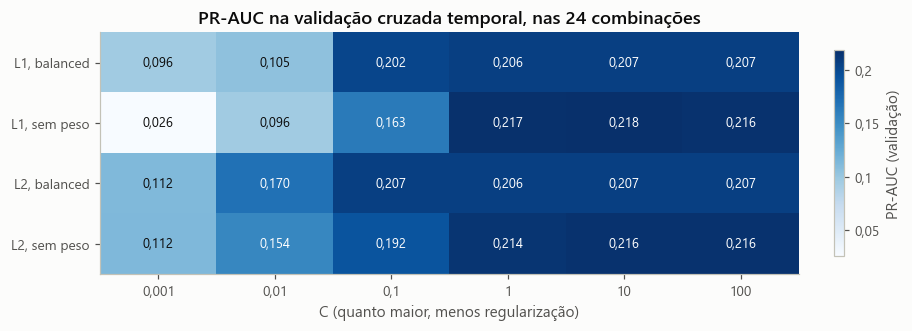

**Leitura.** Regularização forte demais (`C` de 0,001 a 0,01) piora a validação: com L2 sem peso, o PR-AUC é 0,112 com `C`=0,001 e 0,214 com `C`=1. A partir de `C`=1, a validação quase não muda. Dar mais peso aos casos raros (`balanced`) não ajudou a ordenar os dias.

In [25]:
# 8.3 Mapa de calor: o que a busca encontrou
tabela_busca["configuração"] = tabela_busca["penalização"] + ", " + tabela_busca["class_weight"]
grade_calor = tabela_busca.pivot(index="configuração", columns="C", values="PR-AUC validação")

fig, ax = plt.subplots(figsize=(8.2, 2.9), constrained_layout=True)
img = ax.imshow(grade_calor.values, cmap="Blues", aspect="auto", vmin=np.nanmin(grade_calor.values), vmax=np.nanmax(grade_calor.values))
ax.set_xticks(range(grade_calor.shape[1]), [virgula(f"{c:g}") for c in grade_calor.columns])
ax.set_yticks(range(grade_calor.shape[0]), grade_calor.index)
ax.set_xlabel("C (quanto maior, menos regularização)")
ax.set_title("PR-AUC na validação cruzada temporal, nas 24 combinações")
ax.grid(False)
faixa_calor = np.nanmax(grade_calor.values) - np.nanmin(grade_calor.values)
for (lin, col), v in np.ndenumerate(grade_calor.values):
    claro = (v - np.nanmin(grade_calor.values)) / faixa_calor > 0.55
    ax.text(col, lin, virgula(f"{v:.3f}"), ha="center", va="center", fontsize=8.5, color="white" if claro else "#0b0b0b")
fig.colorbar(img, ax=ax, shrink=0.85, label="PR-AUC (validação)")
salvar(fig, "busca_mapa_calor")

sem_peso_l2 = grade_calor.loc["L2, sem peso"]
display(Markdown(virgula(f"**Leitura.** Regularização forte demais (`C` de 0,001 a 0,01) piora a validação: com L2 sem peso, o PR-AUC é {sem_peso_l2[0.001]:.3f} com `C`=0,001 e {sem_peso_l2[1.0]:.3f} com `C`=1. A partir de `C`=1, a validação quase não muda. Dar mais peso aos casos raros (`balanced`) não ajudou a ordenar os dias.")))

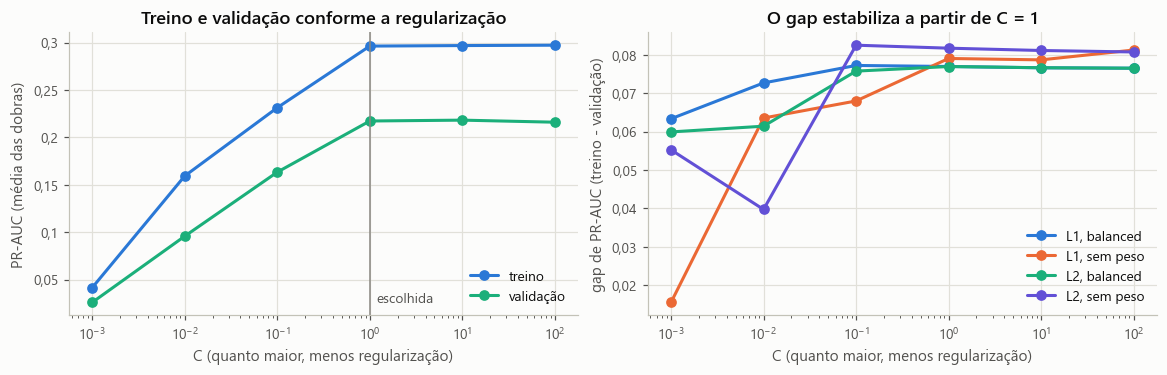

**Leitura.** Sinal clássico de overfitting é o treino subir enquanto a validação cai conforme o modelo fica mais flexível. Aqui, de `C`=1 a `C`=100, o treino vai de 0,296 para 0,297 e a validação, de 0,217 para 0,216. O modelo tem poucos parâmetros: o gap sobe junto com o desempenho até `C`=1 e depois fica estável. A seção 9.10 discute o gap que existe.

In [26]:
# 8.4 Complexidade x desempenho: como o overfitting apareceria
recorte = tabela_busca[(tabela_busca["penalização"] == escolhida["penalização"]) & (tabela_busca["class_weight"] == escolhida["class_weight"])].sort_values("C")

fig, eixos = plt.subplots(1, 2, figsize=(10.5, 3.3), constrained_layout=True)
eixos[0].plot(recorte["C"], recorte["PR-AUC treino"], marker="o", color=AZUL, label="treino")
eixos[0].plot(recorte["C"], recorte["PR-AUC validação"], marker="o", color=AQUA, label="validação")
eixos[0].axvline(PARAMS["C"], color=CINZA, linewidth=1)
eixos[0].annotate("escolhida", (PARAMS["C"], recorte["PR-AUC validação"].min()), xytext=(4, 0), textcoords="offset points", fontsize=9, color="#52514e")
eixos[0].set_xscale("log")
eixos[0].set_xlabel("C (quanto maior, menos regularização)")
eixos[0].set_ylabel("PR-AUC (média das dobras)")
eixos[0].set_title("Treino e validação conforme a regularização")
eixos[0].legend(loc="lower right")

for (config, grupo_cfg), cor in zip(tabela_busca.groupby("configuração"), [AZUL, LARANJA, AQUA, "#6250d6"]):
    grupo_cfg = grupo_cfg.sort_values("C")
    eixos[1].plot(grupo_cfg["C"], grupo_cfg["gap treino - validação"], marker="o", color=cor, label=config)
eixos[1].set_xscale("log")
eixos[1].set_xlabel("C (quanto maior, menos regularização)")
eixos[1].set_ylabel("gap de PR-AUC (treino - validação)")
eixos[1].set_title("O gap estabiliza a partir de C = 1")
eixos[1].legend(loc="lower right")
salvar(fig, "busca_overfitting")

display(Markdown(virgula(f"**Leitura.** Sinal clássico de overfitting é o treino subir enquanto a validação cai conforme o modelo fica mais flexível. Aqui, de `C`=1 a `C`=100, o treino vai de {recorte.set_index('C').loc[1.0, 'PR-AUC treino']:.3f} para {recorte.set_index('C').loc[100.0, 'PR-AUC treino']:.3f} e a validação, de {recorte.set_index('C').loc[1.0, 'PR-AUC validação']:.3f} para {recorte.set_index('C').loc[100.0, 'PR-AUC validação']:.3f}. O modelo tem poucos parâmetros: o gap sobe junto com o desempenho até `C`=1 e depois fica estável. A seção 9.10 discute o gap que existe.")))

## 9. Resultados em treino e teste

A partir daqui o modelo é avaliado em 2025. Modelo, variáveis, hiperparâmetros e limiares já estão congelados com base apenas no treino. Todos os resultados desta seção usam só a informação que existe na manhã do dia.

In [27]:
# 9.1 Treino final com a combinação escolhida, em todo o período de treino
modelo = criar_logistica(NUM_FINAIS, CAT_FINAIS, **PARAMS).fit(X_treino, y_treino)

X_teste = teste[VARIAVEIS]
y_teste = teste["alagou"].to_numpy()
prob_treino = modelo.predict_proba(X_treino)[:, 1]
prob_teste = modelo.predict_proba(X_teste)[:, 1]

# Previsão fora da amostra dentro do treino: cada dobra é prevista por um modelo treinado apenas com o passado.
prob_oof = np.full(len(treino), np.nan)
for tr, va in dobras:
    m = criar_logistica(NUM_FINAIS, CAT_FINAIS, **PARAMS).fit(X_treino.iloc[tr], y_treino[tr])
    prob_oof[va] = m.predict_proba(X_treino.iloc[va])[:, 1]
tem_oof = ~np.isnan(prob_oof)
y_oof, p_oof = y_treino[tem_oof], prob_oof[tem_oof]
print(f"Linhas com previsão fora da amostra no treino: {tem_oof.sum()} de {len(treino)}")

Linhas com previsão fora da amostra no treino: 19360 de 23392


In [28]:
# 9.2 Limiares dos níveis de atenção, definidos só com o treino (previsões fora da amostra)
ALVO_RECALL_MEDIO = 0.80  # o nível "médio ou alto" deve cobrir pelo menos 80% dos alagamentos

precisoes, recalls, limiares = precision_recall_curve(y_oof, p_oof)

def limiar_para_recall(alvo):
    # O maior limiar que ainda cobre a fração desejada dos alagamentos.
    return float(limiares[recalls[:-1] >= alvo].max())

LIMIAR_MEDIO = limiar_para_recall(ALVO_RECALL_MEDIO)
# Alto: o limiar que maximiza o F1 na validação, ou seja, onde o nível alto equilibra precisão e recall.
f1s = 2 * precisoes[:-1] * recalls[:-1] / np.maximum(precisoes[:-1] + recalls[:-1], 1e-12)
LIMIAR_ALTO = float(limiares[np.argmax(f1s)])
assert LIMIAR_ALTO > LIMIAR_MEDIO

def nivel_atencao(prob):
    return np.select([prob >= LIMIAR_ALTO, prob >= LIMIAR_MEDIO], ["alto", "médio"], default="baixo")

# O que custa cada alvo de cobertura (só com as previsões fora da amostra do treino).
compromisso = []
for alvo in (0.6, 0.7, 0.8, 0.9):
    limiar_alvo = limiar_para_recall(alvo)
    marcado = p_oof >= limiar_alvo
    compromisso.append({"alagamentos cobertos": f"{alvo:.0%}", "limiar": limiar_alvo, "% das linhas em atenção": marcado.mean() * 100,
                        "precisão (%)": y_oof[marcado].mean() * 100, "dias por ano em cada subprefeitura": marcado.mean() * 365})
tabela_compromisso = pd.DataFrame(compromisso).set_index("alagamentos cobertos")
display(tabela_compromisso.round(3))
print(virgula(f"Limiar do nível médio: probabilidade >= {LIMIAR_MEDIO:.4f}"))
print(virgula(f"Limiar do nível alto:  probabilidade >= {LIMIAR_ALTO:.4f}"))
display(Markdown(virgula(f"**Leitura.** Cobrir mais alagamentos custa mais dias em atenção. O alvo de 80% é uma escolha de projeto, e na validação ele equivale a cerca de {tabela_compromisso.loc['80%', 'dias por ano em cada subprefeitura']:.0f} dias por ano em cada subprefeitura. Quem usar o Elo pode preferir outro ponto da tabela: é uma decisão de produto, a ser discutida com a comunidade.")))

,limiar,% das linhas em atenção,precisão (%),dias por ano em cada subprefeitura
alagamentos cobertos,,,,
60%,0.079,10.134,15.392,36.990
70%,0.054,13.905,13.076,50.753
80%,0.031,21.989,9.443,80.259
90%,0.018,34.494,6.768,125.902


Limiar do nível médio: probabilidade >= 0,0307
Limiar do nível alto:  probabilidade >= 0,1066


**Leitura.** Cobrir mais alagamentos custa mais dias em atenção. O alvo de 80% é uma escolha de projeto, e na validação ele equivale a cerca de 80 dias por ano em cada subprefeitura. Quem usar o Elo pode preferir outro ponto da tabela: é uma decisão de produto, a ser discutida com a comunidade.

In [29]:
# 9.3 Métricas de treino, validação e teste lado a lado
def calcular_metricas(y, p, limiar):
    pred = (p >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "ROC-AUC": roc_auc_score(y, p),
        "PR-AUC": average_precision_score(y, p),
        "Brier": brier_score_loss(y, p),
        "Precisão": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Especificidade": tn / (tn + fp),
        "Prevalência": float(np.mean(y)),
    }

def tabela_lado_a_lado(limiar):
    return pd.DataFrame({
        "Treino": calcular_metricas(y_treino, prob_treino, limiar),
        "Validação (CV, fora da amostra)": calcular_metricas(y_oof, p_oof, limiar),
        "Teste (2025)": calcular_metricas(y_teste, prob_teste, limiar),
    })

# "Médio ou alto" é o ponto em que o coordenador se prepara. "Alto" é o ponto em que a chamada abre.
ponto_operacao = LIMIAR_MEDIO
lado_a_lado = tabela_lado_a_lado(LIMIAR_MEDIO)
lado_a_lado_alto = tabela_lado_a_lado(LIMIAR_ALTO)
print("Limiar do nível médio (preparar):")
display(lado_a_lado.round(4))
print("Limiar do nível alto (abrir a chamada):")
display(lado_a_lado_alto.round(4))
lado_a_lado.to_csv(RESULTADOS / "metricas_treino_validacao_teste.csv")
lado_a_lado_alto.to_csv(RESULTADOS / "metricas_nivel_alto.csv")

gap_pr_treino_teste = lado_a_lado.loc["PR-AUC", "Treino"] - lado_a_lado.loc["PR-AUC", "Teste (2025)"]
gap_pr_cv_teste = lado_a_lado.loc["PR-AUC", "Validação (CV, fora da amostra)"] - lado_a_lado.loc["PR-AUC", "Teste (2025)"]
gap_roc_treino_teste = lado_a_lado.loc["ROC-AUC", "Treino"] - lado_a_lado.loc["ROC-AUC", "Teste (2025)"]
print(virgula(f"Gap PR-AUC treino - teste: {gap_pr_treino_teste:+.3f} | validação - teste: {gap_pr_cv_teste:+.3f} | gap ROC-AUC treino - teste: {gap_roc_treino_teste:+.3f}"))
display(Markdown("**Atenção à coluna de validação.** O limiar do nível médio foi escolhido para cobrir 80% dos alagamentos nessas mesmas previsões, então o recall de validação é o alvo, e não um resultado. A coluna reúne as previsões fora da amostra das 5 dobras; a seção 8 usa a média do PR-AUC de cada dobra, por isso os dois valores diferem um pouco."))

Limiar do nível médio (preparar):


,Treino,"Validação (CV, fora da amostra)",Teste (2025)
ROC-AUC,0.8849,0.8746,0.8600
PR-AUC,0.2452,0.1905,0.1762
Brier,0.0275,0.0230,0.0257
Precisão,0.1214,0.0944,0.1088
Recall,0.8196,0.8008,0.7463
F1,0.2115,0.1689,0.1899
Especificidade,0.7995,0.7956,0.8172
Prevalência,0.0327,0.0259,0.0290


Limiar do nível alto (abrir a chamada):


,Treino,"Validação (CV, fora da amostra)",Teste (2025)
ROC-AUC,0.8849,0.8746,0.8600
PR-AUC,0.2452,0.1905,0.1762
Brier,0.0275,0.0230,0.0257
Precisão,0.2097,0.1791,0.1916
Recall,0.5255,0.5159,0.4159
F1,0.2998,0.2659,0.2623
Especificidade,0.9330,0.9371,0.9475
Prevalência,0.0327,0.0259,0.0290


Gap PR-AUC treino - teste: +0,069 | validação - teste: +0,014 | gap ROC-AUC treino - teste: +0,025


**Atenção à coluna de validação.** O limiar do nível médio foi escolhido para cobrir 80% dos alagamentos nessas mesmas previsões, então o recall de validação é o alvo, e não um resultado. A coluna reúne as previsões fora da amostra das 5 dobras; a seção 8 usa a média do PR-AUC de cada dobra, por isso os dois valores diferem um pouco.

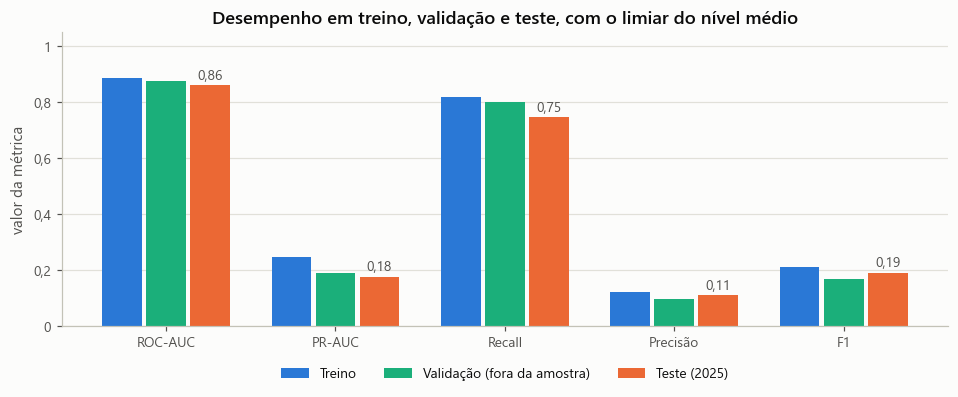

**Leitura.** O ROC-AUC é alto nos três conjuntos (0,88, 0,87 e 0,86) porque os muitos dias secos são fáceis de separar. O PR-AUC, que olha só o topo da lista, mostra o limite real: 0,18 no teste. A precisão baixa (11%) indica que a maior parte dos dias em atenção não teve registro de alagamento.

In [30]:
# 9.4 Gráfico: treino e teste lado a lado
metricas_grafico = ["ROC-AUC", "PR-AUC", "Recall", "Precisão", "F1"]
x = np.arange(len(metricas_grafico))
largura = 0.26

fig, ax = plt.subplots(figsize=(8.6, 3.5), constrained_layout=True)
ax.bar(x - largura, lado_a_lado.loc[metricas_grafico, "Treino"], largura * 0.9, color=AZUL, label="Treino")
ax.bar(x, lado_a_lado.loc[metricas_grafico, "Validação (CV, fora da amostra)"], largura * 0.9, color=AQUA, label="Validação (fora da amostra)")
barras_teste = ax.bar(x + largura, lado_a_lado.loc[metricas_grafico, "Teste (2025)"], largura * 0.9, color=LARANJA, label="Teste (2025)")
ax.bar_label(barras_teste, labels=[virgula(f"{v:.2f}") for v in lado_a_lado.loc[metricas_grafico, "Teste (2025)"]], padding=2, fontsize=9, color="#52514e")
ax.set_xticks(x, metricas_grafico)
ax.set_ylim(0, 1.05)
ax.set_ylabel("valor da métrica")
ax.set_title("Desempenho em treino, validação e teste, com o limiar do nível médio")
ax.xaxis.grid(False)
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
salvar(fig, "treino_validacao_teste")
display(Markdown(virgula(f"**Leitura.** O ROC-AUC é alto nos três conjuntos ({lado_a_lado.loc['ROC-AUC', 'Treino']:.2f}, {lado_a_lado.loc['ROC-AUC', 'Validação (CV, fora da amostra)']:.2f} e {lado_a_lado.loc['ROC-AUC', 'Teste (2025)']:.2f}) porque os muitos dias secos são fáceis de separar. O PR-AUC, que olha só o topo da lista, mostra o limite real: {lado_a_lado.loc['PR-AUC', 'Teste (2025)']:.2f} no teste. A precisão baixa ({lado_a_lado.loc['Precisão', 'Teste (2025)']:.0%}) indica que a maior parte dos dias em atenção não teve registro de alagamento.")))

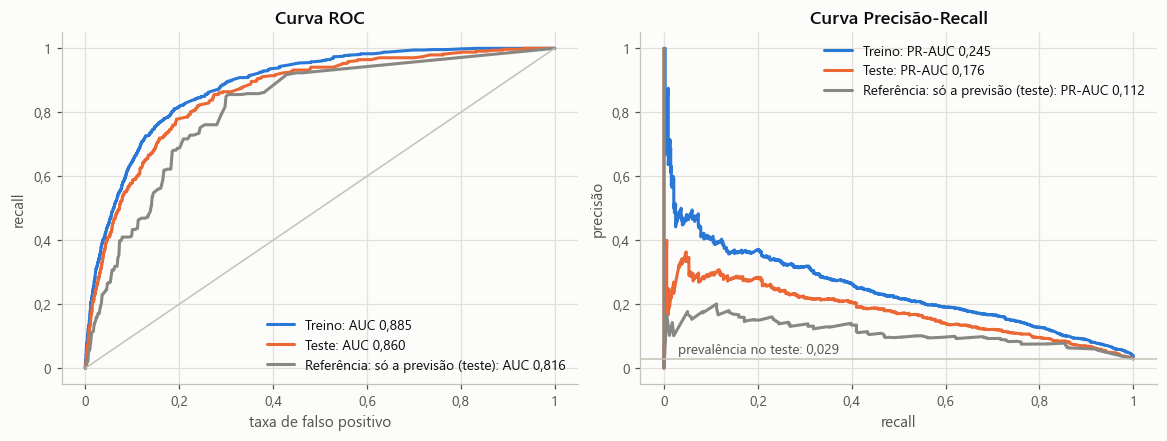

**Leitura.** Na curva ROC, o modelo final tem área de 0,860 no teste, contra 0,816 da referência que só usa a previsão. Na curva Precisão-Recall, a precisão cai rápido: só uma parte pequena dos casos consegue ser identificada com precisão alta, e cobrir mais alagamentos exige aceitar muitos dias sem registro.

In [31]:
# 9.5 Modelos de referência e curvas ROC e Precisão-Recall. Todos usam só o que existe na manhã do dia.
# Referência 1: só a previsão do dia, sem saber o local (o limiar dela é calculado mais adiante, na seção 12.4)
modelo_so_previsao = criar_logistica(PREV_DIA, [], **PARAMS).fit(treino[PREV_DIA], y_treino)
prob_ref = modelo_so_previsao.predict_proba(teste[PREV_DIA])[:, 1]

# Referência 2: só o local, sem previsão. É a frequência histórica de cada subprefeitura no treino.
freq_sub = treino.groupby("subprefeitura")["alagou"].mean()
prob_local = teste["subprefeitura"].map(freq_sub).to_numpy()

# Referência 3: frequência histórica da subprefeitura em cada mês
freq_sub_mes = treino.groupby(["subprefeitura", "mes"])["alagou"].mean().rename("freq").reset_index()
prob_freq = (teste[["subprefeitura", "mes"]].merge(freq_sub_mes, on=["subprefeitura", "mes"], how="left")["freq"]
             .fillna(y_treino.mean()).to_numpy())

# Comparador: o melhor XGBoost encontrado na seção 7.4, com as mesmas variáveis do modelo final
modelo_xgb = clone(CANDIDATOS_FINAIS["XGBoost"][0]).set_params(**configs_finais["XGBoost"]).fit(X_treino, y_treino)
prob_xgb = modelo_xgb.predict_proba(X_teste)[:, 1]

fig, eixos = plt.subplots(1, 2, figsize=(10.5, 3.9), constrained_layout=True)
for y, p, cor, nome in [(y_treino, prob_treino, AZUL, "Treino"), (y_teste, prob_teste, LARANJA, "Teste"),
                        (y_teste, prob_ref, CINZA, "Referência: só a previsão (teste)")]:
    fpr, tpr, _ = roc_curve(y, p)
    eixos[0].plot(fpr, tpr, color=cor, label=virgula(f"{nome}: AUC {roc_auc_score(y, p):.3f}"))
    prec, rec, _ = precision_recall_curve(y, p)
    eixos[1].plot(rec, prec, color=cor, label=virgula(f"{nome}: PR-AUC {average_precision_score(y, p):.3f}"))
eixos[0].plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1)
eixos[0].set_xlabel("taxa de falso positivo")
eixos[0].set_ylabel("recall")
eixos[0].set_title("Curva ROC")
eixos[0].legend(loc="lower right")
eixos[1].axhline(y_teste.mean(), color="#c3c2b7", linewidth=1)
eixos[1].annotate(virgula(f"prevalência no teste: {y_teste.mean():.3f}"), (0.03, y_teste.mean()), ha="left", va="bottom", fontsize=9, color="#52514e", xytext=(0, 2), textcoords="offset points")
eixos[1].set_xlabel("recall")
eixos[1].set_ylabel("precisão")
eixos[1].set_title("Curva Precisão-Recall")
eixos[1].legend(loc="upper right")
salvar(fig, "curvas_roc_pr")
display(Markdown(virgula(f"**Leitura.** Na curva ROC, o modelo final tem área de {roc_auc_score(y_teste, prob_teste):.3f} no teste, contra {roc_auc_score(y_teste, prob_ref):.3f} da referência que só usa a previsão. Na curva Precisão-Recall, a precisão cai rápido: só uma parte pequena dos casos consegue ser identificada com precisão alta, e cobrir mais alagamentos exige aceitar muitos dias sem registro.")))

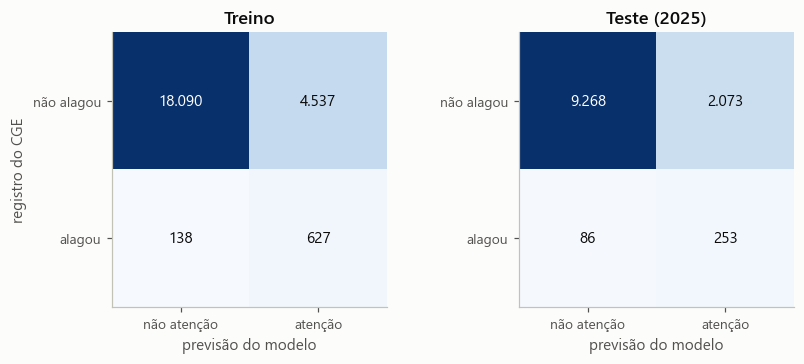

**Leitura.** No teste, 253 alagamentos foram cobertos e 86 ficaram de fora. Em troca, 2.073 subprefeitura-dias entraram em atenção sem registro de alagamento: é o custo de cobrir a maior parte dos casos.

In [32]:
# 9.6 Matrizes de confusão em treino e teste (limiar: nível médio ou alto)
matrizes = {"Treino": confusion_matrix(y_treino, (prob_treino >= ponto_operacao).astype(int)),
            "Teste (2025)": confusion_matrix(y_teste, (prob_teste >= ponto_operacao).astype(int))}

fig, eixos = plt.subplots(1, 2, figsize=(7.6, 3.2), constrained_layout=True)
for eixo, (nome, mat) in zip(eixos, matrizes.items()):
    eixo.imshow(mat, cmap="Blues", vmin=0, vmax=mat.max())
    eixo.set_xticks([0, 1], ["não atenção", "atenção"])
    eixo.set_yticks([0, 1], ["não alagou", "alagou"])
    eixo.set_xlabel("previsão do modelo")
    eixo.set_title(nome)
    eixo.grid(False)
    for (lin, col), v in np.ndenumerate(mat):
        eixo.text(col, lin, f"{v:,}".replace(",", "."), ha="center", va="center", fontsize=10,
                  color="white" if v > mat.max() * 0.6 else "#0b0b0b")
eixos[0].set_ylabel("registro do CGE")
salvar(fig, "matrizes_confusao")
mt = matrizes["Teste (2025)"]
falsos_texto = f"{mt[0, 1]:,}".replace(",", ".")
display(Markdown(f"**Leitura.** No teste, {mt[1, 1]} alagamentos foram cobertos e {mt[1, 0]} ficaram de fora. Em troca, {falsos_texto} subprefeitura-dias entraram em atenção sem registro de alagamento: é o custo de cobrir a maior parte dos casos."))

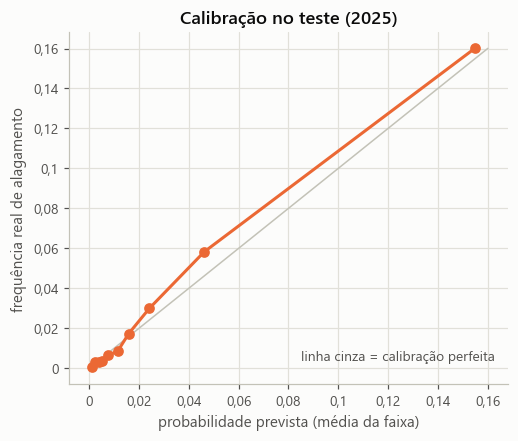

Probabilidade média prevista no teste: 0,027 | frequência real no teste: 0,029


**Leitura.** Nas nove faixas de menor probabilidade, previsto e real ficam próximos (diferença média de 0,3 ponto percentual). Na faixa mais alta, o modelo prevê 15,5% e acontece 16,0%. Em média, previu 2,7% e a frequência real foi 2,9%. A seção 10 faz a comparação por nível.

In [33]:
# 9.7 Calibração: quando o modelo diz 30%, acontece em cerca de 30% das vezes?
frac_pos, media_prob = calibration_curve(y_teste, prob_teste, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(4.6, 3.9), constrained_layout=True)
limite_eixo = max(media_prob.max(), frac_pos.max())
ax.plot([0, limite_eixo], [0, limite_eixo], color="#c3c2b7", linewidth=1)
ax.plot(media_prob, frac_pos, marker="o", color=LARANJA)
ax.text(0.97, 0.06, "linha cinza = calibração perfeita", transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color="#52514e")
ax.set_xlabel("probabilidade prevista (média da faixa)")
ax.set_ylabel("frequência real de alagamento")
ax.set_title("Calibração no teste (2025)")
salvar(fig, "calibracao")
print(virgula(f"Probabilidade média prevista no teste: {prob_teste.mean():.3f} | frequência real no teste: {y_teste.mean():.3f}"))
erro_faixas = np.mean(np.abs(media_prob[:-1] - frac_pos[:-1])) * 100
display(Markdown(virgula(f"**Leitura.** Nas nove faixas de menor probabilidade, previsto e real ficam próximos (diferença média de {erro_faixas:.1f} ponto percentual). Na faixa mais alta, o modelo prevê {media_prob[-1]:.1%} e acontece {frac_pos[-1]:.1%}. Em média, previu {prob_teste.mean():.1%} e a frequência real foi {y_teste.mean():.1%}. A seção 10 faz a comparação por nível.")))

In [34]:
# 9.8 Incerteza do resultado de teste (bootstrap por DIA, pois linhas do mesmo dia são correlacionadas)
codigos_dia, dias_unicos = pd.factorize(teste["data"])
linhas_do_dia = [np.flatnonzero(codigos_dia == i) for i in range(len(dias_unicos))]

def reamostrar_dias(rng):
    # Sorteia dias inteiros com reposição, mantendo juntas as 32 subprefeituras de cada dia.
    return np.concatenate([linhas_do_dia[i] for i in rng.integers(0, len(linhas_do_dia), len(linhas_do_dia))])

def bootstrap_por_dia(y, p, funcao, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    valores = []
    for _ in range(n):
        idx = reamostrar_dias(rng)
        if y[idx].min() != y[idx].max():
            valores.append(funcao(y[idx], p[idx]))
    return np.percentile(valores, [2.5, 97.5])

def diferenca_pareada(p_a, p_b, funcao, n=1000):
    # Mesma reamostragem de dias para os dois modelos.
    rng = np.random.default_rng(SEED)
    valores = []
    for _ in range(n):
        idx = reamostrar_dias(rng)
        if y_teste[idx].min() != y_teste[idx].max():
            valores.append(funcao(y_teste[idx], p_a[idx]) - funcao(y_teste[idx], p_b[idx]))
    return np.percentile(valores, [2.5, 97.5])

previsoes_teste = {"Modelo final": prob_teste, "Só a previsão, sem o local": prob_ref, "Só o local, sem a previsão": prob_local,
                   "Frequência por subprefeitura e mês": prob_freq, "XGBoost (melhor da seção 7.4)": prob_xgb}

linhas = []
for nome, p in previsoes_teste.items():
    ic_pr = bootstrap_por_dia(y_teste, p, average_precision_score)
    ic_roc = bootstrap_por_dia(y_teste, p, roc_auc_score)
    linha = {"modelo": nome, "PR-AUC": average_precision_score(y_teste, p), "PR-AUC IC95% inferior": ic_pr[0], "PR-AUC IC95% superior": ic_pr[1],
             "ROC-AUC": roc_auc_score(y_teste, p), "ROC-AUC IC95% inferior": ic_roc[0], "ROC-AUC IC95% superior": ic_roc[1]}
    if nome != "Modelo final":
        dif_pr = diferenca_pareada(prob_teste, p, average_precision_score)
        linha["modelo final - este (PR-AUC), IC95% inferior"], linha["modelo final - este (PR-AUC), IC95% superior"] = dif_pr[0], dif_pr[1]
    linhas.append(linha)
tabela_referencias = pd.DataFrame(linhas).set_index("modelo")
display(tabela_referencias.round(3))
print(virgula(f"Acaso (prevalência no teste): PR-AUC {y_teste.mean():.3f} | ROC-AUC 0.500"))

tr = tabela_referencias["PR-AUC"]
dif_xgb = tabela_referencias.loc["XGBoost (melhor da seção 7.4)", ["modelo final - este (PR-AUC), IC95% inferior", "modelo final - este (PR-AUC), IC95% superior"]].to_numpy(dtype=float)
frase_xgb = "o intervalo da diferença inclui o zero, então os dois empatam no teste" if dif_xgb[0] <= 0 <= dif_xgb[1] else "o intervalo da diferença não inclui o zero"
display(Markdown(virgula(f"**De onde vem o resultado.** A previsão sozinha, sem saber o local, faz {tr['Só a previsão, sem o local']:.3f}. O local sozinho, sem a previsão, faz {tr['Só o local, sem a previsão']:.3f}. Juntos, no modelo final, fazem {tr['Modelo final']:.3f}. Parte do ganho vem, portanto, de saber onde o CGE costuma registrar, que é o limite discutido na seção 12. O XGBoost mais ajustado fez {tr['XGBoost (melhor da seção 7.4)']:.3f} no teste: {frase_xgb} (IC95% de {dif_xgb[0]:+.3f} a {dif_xgb[1]:+.3f}).")))

,PR-AUC,PR-AUC IC95% inferior,PR-AUC IC95% superior,ROC-AUC,ROC-AUC IC95% inferior,ROC-AUC IC95% superior,"modelo final - este (PR-AUC), IC95% inferior","modelo final - este (PR-AUC), IC95% superior"
modelo,,,,,,,,
Modelo final,0.176,0.120,0.252,0.860,0.825,0.896,NaN,NaN
"Só a previsão, sem o local",0.112,0.076,0.168,0.816,0.766,0.863,0.041,0.093
"Só o local, sem a previsão",0.058,0.042,0.075,0.707,0.687,0.727,0.069,0.192
Frequência por subprefeitura e mês,0.107,0.071,0.151,0.776,0.733,0.812,0.010,0.147
XGBoost (melhor da seção 7.4),0.173,0.117,0.246,0.857,0.816,0.895,-0.018,0.027


Acaso (prevalência no teste): PR-AUC 0,029 | ROC-AUC 0,500


**De onde vem o resultado.** A previsão sozinha, sem saber o local, faz 0,112. O local sozinho, sem a previsão, faz 0,058. Juntos, no modelo final, fazem 0,176. Parte do ganho vem, portanto, de saber onde o CGE costuma registrar, que é o limite discutido na seção 12. O XGBoost mais ajustado fez 0,173 no teste: o intervalo da diferença inclui o zero, então os dois empatam no teste (IC95% de -0,018 a +0,027).

In [35]:
# 9.8b Só para registro: a margem da regra de escolha muda o resultado no teste? Nada é escolhido aqui.
linhas = []
for margem, linha_margem in sensibilidade_margem.iterrows():
    params_margem = {"C": float(linha_margem["C"]), "l1_ratio": 1.0 if linha_margem["penalização"] == "L1" else 0.0,
                     "class_weight": "balanced" if linha_margem["class_weight"] == "balanced" else None}
    p_margem = criar_logistica(NUM_FINAIS, CAT_FINAIS, **params_margem).fit(X_treino, y_treino).predict_proba(X_teste)[:, 1]
    linhas.append({"margem": margem, "C": params_margem["C"], "PR-AUC validação": linha_margem["PR-AUC validação"], "PR-AUC teste": average_precision_score(y_teste, p_margem)})
sensibilidade_teste = pd.DataFrame(linhas).set_index("margem")
display(sensibilidade_teste.round(4))

,C,PR-AUC validação,PR-AUC teste
margem,,,
0.000,10.0,0.2182,0.1756
0.002,1.0,0.2173,0.1762
0.005,1.0,0.2173,0.1762
0.010,1.0,0.2173,0.1762


In [36]:
# 9.9 Robustez: e nos dias em que choveu de fato? Nos dias secos, acertar é fácil e infla as métricas.
def metricas_dia_chuva(df, p):
    mascara = (df["inmet_chuva_A701"].fillna(0) >= 1).to_numpy() | (df["inmet_chuva_A771"].fillna(0) >= 1).to_numpy()
    return {"linhas": int(mascara.sum()), "PR-AUC": average_precision_score(df["alagou"][mascara], p[mascara]),
            "ROC-AUC": roc_auc_score(df["alagou"][mascara], p[mascara]), "prevalência": df["alagou"][mascara].mean()}

quadro_chuva = pd.DataFrame({"Treino": metricas_dia_chuva(treino, prob_treino),
                             "Teste (2025)": metricas_dia_chuva(teste, prob_teste),
                             "Só a previsão, sem o local (teste)": metricas_dia_chuva(teste, prob_ref)})
display(quadro_chuva.round(4))
display(Markdown(virgula(f"**Leitura.** Olhando só os dias em que choveu de fato, que são os difíceis, o ROC-AUC do teste cai de {lado_a_lado.loc['ROC-AUC', 'Teste (2025)']:.2f} para {quadro_chuva.loc['ROC-AUC', 'Teste (2025)']:.2f}. É um número mais honesto para quem se pergunta se o modelo ajuda quando realmente chove.")))

,Treino,Teste (2025),"Só a previsão, sem o local (teste)"
linhas,8544.0000,3936.0000,3936.0000
PR-AUC,0.2841,0.2104,0.1325
ROC-AUC,0.7814,0.7533,0.6423
prevalência,0.0873,0.0833,0.0833


**Leitura.** Olhando só os dias em que choveu de fato, que são os difíceis, o ROC-AUC do teste cai de 0,86 para 0,75. É um número mais honesto para quem se pergunta se o modelo ajuda quando realmente chove.

### 9.10 Discussão de overfitting

**Convenção adotada.** O overfitting é medido pela queda relativa do PR-AUC ao sair do treino: até 10% é leve, de 10% a 30% é moderado, acima de 30% é forte. Esses cortes são uma convenção deste trabalho, sem fonte externa: servem para deixar a leitura explícita, e os números ficam ao lado. Como o PR-AUC depende da proporção de casos, a comparação também é feita em múltiplos do acaso (PR-AUC dividido pela prevalência). O segundo sinal é o clássico: a validação piorar quando o modelo fica mais complexo.

São duas perguntas diferentes, e elas ficam separadas abaixo. O modelo decorou o treino? E a validação antecipou bem o resultado do teste?

In [37]:
# 9.11 Texto de overfitting gerado a partir dos números calculados
linha = lado_a_lado

def classe_overfitting(queda):
    return "leve" if queda <= 0.10 else "moderado" if queda <= 0.30 else "forte"

pr_treino_cv, pr_validacao_cv = escolhida["PR-AUC treino"], escolhida["PR-AUC validação"]
queda_cv = (pr_treino_cv - pr_validacao_cv) / pr_treino_cv
pr_treino, pr_oof, pr_teste = (linha.loc["PR-AUC", c] for c in ["Treino", "Validação (CV, fora da amostra)", "Teste (2025)"])
queda_teste = (pr_treino - pr_teste) / pr_treino
lift_treino, lift_oof, lift_teste = pr_treino / y_treino.mean(), pr_oof / y_oof.mean(), pr_teste / y_teste.mean()
mais_flexivel = recorte.iloc[-1]
mais_rigida_util = recorte[recorte["C"] == PARAMS["C"]].iloc[0]

texto = f'''
**O modelo decorou o treino?**

- Na validação cruzada, o PR-AUC vai de {pr_treino_cv:.3f} no treino das dobras para {pr_validacao_cv:.3f} na validação: queda de {queda_cv:.0%}, que pelo critério é **{classe_overfitting(queda_cv)}**.
- Do treino final para o teste, vai de {pr_treino:.3f} para {pr_teste:.3f}: queda de {queda_teste:.0%}, também **{classe_overfitting(queda_teste)}** pelo critério. Em múltiplos do acaso, vai de {lift_treino:.1f} vezes para {lift_teste:.1f} vezes.
- O sinal clássico não aparece. Com menos regularização (de `C`={PARAMS["C"]:g} para `C`={mais_flexivel["C"]:g}), o treino passa de {mais_rigida_util["PR-AUC treino"]:.3f} para {mais_flexivel["PR-AUC treino"]:.3f} e a validação, de {mais_rigida_util["PR-AUC validação"]:.3f} para {mais_flexivel["PR-AUC validação"]:.3f}. O gap não cresce.
- Portanto, a diferença entre treino e fora da amostra existe, mas não vem de excesso de flexibilidade: a validação é sempre um período posterior e o mesmo modelo, simples, encontra outro ano e outro padrão de chuva e de registro.

**A validação antecipou o teste?** É outra pergunta, e diz se a estimativa é estável, não se há pouco overfitting. A resposta depende de qual validação se olha. Com as previsões das dobras reunidas, o PR-AUC é {pr_oof:.3f}, e o teste ({pr_teste:.3f}) fica {(pr_oof - pr_teste) / pr_oof:.0%} abaixo. Na média das dobras, que é a métrica usada para escolher o modelo, é {pr_validacao_cv:.3f}, e o teste fica {(pr_validacao_cv - pr_teste) / pr_validacao_cv:.0%} abaixo. A métrica de escolha foi, portanto, otimista.
'''
display(Markdown(virgula(texto)))


**O modelo decorou o treino?**

- Na validação cruzada, o PR-AUC vai de 0,296 no treino das dobras para 0,217 na validação: queda de 27%, que pelo critério é **moderado**.
- Do treino final para o teste, vai de 0,245 para 0,176: queda de 28%, também **moderado** pelo critério. Em múltiplos do acaso, vai de 7,5 vezes para 6,1 vezes.
- O sinal clássico não aparece. Com menos regularização (de `C`=1 para `C`=100), o treino passa de 0,296 para 0,297 e a validação, de 0,217 para 0,216. O gap não cresce.
- Portanto, a diferença entre treino e fora da amostra existe, mas não vem de excesso de flexibilidade: a validação é sempre um período posterior e o mesmo modelo, simples, encontra outro ano e outro padrão de chuva e de registro.

**A validação antecipou o teste?** É outra pergunta, e diz se a estimativa é estável, não se há pouco overfitting. A resposta depende de qual validação se olha. Com as previsões das dobras reunidas, o PR-AUC é 0,190, e o teste (0,176) fica 7% abaixo. Na média das dobras, que é a métrica usada para escolher o modelo, é 0,217, e o teste fica 19% abaixo. A métrica de escolha foi, portanto, otimista.


## 10. Níveis de atenção: o resultado na forma como o coordenador vai ver

A probabilidade vira três níveis, com limiares definidos **somente com o treino** (seção 9.2):

- **Médio ou alto** significa "vale deixar a chamada pronta": o limiar captura pelo menos 80% dos alagamentos nas previsões fora da amostra do treino.
- **Alto** significa "abra a chamada": é o limiar de melhor equilíbrio entre precisão e recall (F1).

In [38]:
# 10.1 Resumo por nível em treino e teste, com a probabilidade prevista ao lado da frequência real
def resumo_niveis(y, p):
    niveis = nivel_atencao(p)
    linhas = []
    for nome in ["baixo", "médio", "alto"]:
        m = niveis == nome
        linhas.append({
            "nível": nome,
            "% das linhas": m.mean() * 100,
            "probabilidade média prevista (%)": p[m].mean() * 100,
            "% com alagamento registrado": y[m].mean() * 100,
            "% dos alagamentos": y[m].sum() / y.sum() * 100,
            "linhas": int(m.sum()),
            "alagamentos": int(y[m].sum()),
        })
    return pd.DataFrame(linhas).set_index("nível")

niveis_teste = resumo_niveis(y_teste, prob_teste)
niveis_treino = resumo_niveis(y_oof, p_oof)
print("Validação fora da amostra (treino):")
display(niveis_treino.round(1))
print("Teste (2025):")
display(niveis_teste.round(1))

perdidos_teste = niveis_teste.loc["baixo", "% dos alagamentos"]
cauda_alta = prob_teste > 0.30
cobertura_alto = niveis_teste.loc["alto", "% dos alagamentos"]
acerto_alto = niveis_teste.loc["alto", "% com alagamento registrado"]
dias_atencao = (nivel_atencao(prob_teste) != "baixo").sum() / teste["subprefeitura"].nunique()
dias_alto = (nivel_atencao(prob_teste) == "alto").sum() / teste["subprefeitura"].nunique()
display(Markdown(virgula(f"**Leitura.** Quando o nível é alto, a probabilidade média prevista é de {niveis_teste.loc['alto', 'probabilidade média prevista (%)']:.1f}%, e a frequência real foi de {acerto_alto:.1f}%. No médio, {niveis_teste.loc['médio', 'probabilidade média prevista (%)']:.1f}% e {niveis_teste.loc['médio', '% com alagamento registrado']:.1f}%. No baixo, {niveis_teste.loc['baixo', 'probabilidade média prevista (%)']:.1f}% e {niveis_teste.loc['baixo', '% com alagamento registrado']:.1f}%. Nas previsões acima de 30% ({int(cauda_alta.sum())} casos), o modelo fica otimista: prevê {prob_teste[cauda_alta].mean():.1%}, e a frequência real foi de {y_teste[cauda_alta].mean():.1%}. Só o nível alto abre a chamada: em 2025, isso aconteceria em {cobertura_alto:.0f}% dos alagamentos registrados, e {acerto_alto:.0f}% das chamadas coincidiriam com alagamento registrado. O teste rápido citado no escopo relatava 44% dos casos no nível baixo, com outra base, outro modelo e outro critério de nível, então não dá para comparar os números.")))

Validação fora da amostra (treino):


,% das linhas,probabilidade média prevista (%),% com alagamento registrado,% dos alagamentos,linhas,alagamentos
nível,,,,,,
baixo,78.0,0.9,0.7,19.9,15103,100
médio,14.5,5.6,5.1,28.5,2811,143
alto,7.5,21.2,17.9,51.6,1446,259


Teste (2025):


,% das linhas,probabilidade média prevista (%),% com alagamento registrado,% dos alagamentos,linhas,alagamentos
nível,,,,,,
baixo,80.1,0.9,0.9,25.4,9354,86
médio,13.6,5.7,7.0,33.0,1590,112
alto,6.3,19.5,19.2,41.6,736,141


**Leitura.** Quando o nível é alto, a probabilidade média prevista é de 19,5%, e a frequência real foi de 19,2%. No médio, 5,7% e 7,0%. No baixo, 0,9% e 0,9%. Nas previsões acima de 30% (95 casos), o modelo fica otimista: prevê 38,6%, e a frequência real foi de 27,4%. Só o nível alto abre a chamada: em 2025, isso aconteceria em 42% dos alagamentos registrados, e 19% das chamadas coincidiriam com alagamento registrado. O teste rápido citado no escopo relatava 44% dos casos no nível baixo, com outra base, outro modelo e outro critério de nível, então não dá para comparar os números.

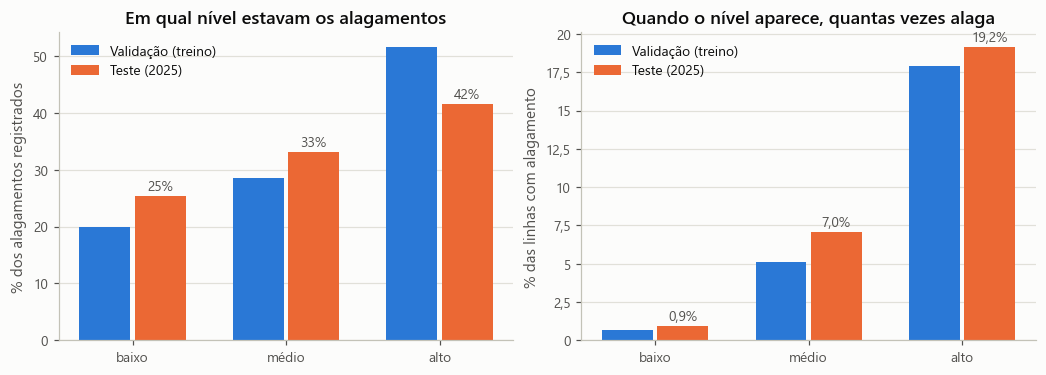

**Leitura.** No painel da direita, a frequência de alagamento sobe com o nível nos dois conjuntos, e os valores de validação e de teste ficam próximos. No painel da esquerda, a cobertura mudou em 2025: o nível alto foi de 51,6% dos alagamentos na validação para 41,6% no teste, e o baixo, de 19,9% para 25,4%. Por isso, os níveis médio e alto cobriram menos do que os 80% buscados na validação.

In [39]:
# 10.2 Gráfico: para onde foram os alagamentos e quantas vezes o nível apareceu
fig, eixos = plt.subplots(1, 2, figsize=(9.4, 3.3), constrained_layout=True)
ordem = ["baixo", "médio", "alto"]
x = np.arange(3)
largura = 0.36

eixos[0].bar(x - largura / 2, niveis_treino.loc[ordem, "% dos alagamentos"], largura * 0.92, color=AZUL, label="Validação (treino)")
barras = eixos[0].bar(x + largura / 2, niveis_teste.loc[ordem, "% dos alagamentos"], largura * 0.92, color=LARANJA, label="Teste (2025)")
eixos[0].bar_label(barras, labels=[f"{v:.0f}%" for v in niveis_teste.loc[ordem, "% dos alagamentos"]], padding=2, fontsize=9, color="#52514e")
eixos[0].set_xticks(x, ordem)
eixos[0].set_ylabel("% dos alagamentos registrados")
eixos[0].set_title("Em qual nível estavam os alagamentos")
eixos[0].xaxis.grid(False)
eixos[0].legend(loc="upper left")

eixos[1].bar(x - largura / 2, niveis_treino.loc[ordem, "% com alagamento registrado"], largura * 0.92, color=AZUL, label="Validação (treino)")
barras = eixos[1].bar(x + largura / 2, niveis_teste.loc[ordem, "% com alagamento registrado"], largura * 0.92, color=LARANJA, label="Teste (2025)")
eixos[1].bar_label(barras, labels=[virgula(f"{v:.1f}%") for v in niveis_teste.loc[ordem, "% com alagamento registrado"]], padding=2, fontsize=9, color="#52514e")
eixos[1].set_xticks(x, ordem)
eixos[1].set_ylabel("% das linhas com alagamento")
eixos[1].set_title("Quando o nível aparece, quantas vezes alaga")
eixos[1].xaxis.grid(False)
eixos[1].legend(loc="upper left")
salvar(fig, "niveis_atencao")
display(Markdown(virgula(f"**Leitura.** No painel da direita, a frequência de alagamento sobe com o nível nos dois conjuntos, e os valores de validação e de teste ficam próximos. No painel da esquerda, a cobertura mudou em 2025: o nível alto foi de {niveis_treino.loc['alto', '% dos alagamentos']:.1f}% dos alagamentos na validação para {niveis_teste.loc['alto', '% dos alagamentos']:.1f}% no teste, e o baixo, de {niveis_treino.loc['baixo', '% dos alagamentos']:.1f}% para {niveis_teste.loc['baixo', '% dos alagamentos']:.1f}%. Por isso, os níveis médio e alto cobriram menos do que os 80% buscados na validação.")))

## 11. Cenário comparativo: e se a chuva do dia fosse conhecida?

O modelo principal usa a previsão. Para ter uma ideia de quanto a incerteza da previsão pesa, a mesma regressão é treinada com a chuva **que de fato caiu** no dia, medida em duas estações do INMET e estimada pela reanálise. Esse dado não existe na manhã do dia, então este cenário não serve para operar. Ele também não é um teto do que seria possível: outra forma de medir a chuva poderia ir além. É só uma comparação. Os limiares são recalculados do mesmo jeito, só com o treino.

In [40]:
# 11.1 Cenário comparativo, com a chuva medida no próprio dia
NUM_MEDIDA, CAT_MEDIDA = CHUVA_DIA_MEDIDA, CAT_FINAIS
VARIAVEIS_MEDIDA = NUM_MEDIDA + CAT_MEDIDA
X_treino_medida, X_teste_medida = treino[VARIAVEIS_MEDIDA], teste[VARIAVEIS_MEDIDA]
modelo_medida = criar_logistica(NUM_MEDIDA, CAT_MEDIDA, **PARAMS).fit(X_treino_medida, y_treino)
prob_medida_teste = modelo_medida.predict_proba(X_teste_medida)[:, 1]
prob_medida_treino = modelo_medida.predict_proba(X_treino_medida)[:, 1]

oof_medida = np.full(len(treino), np.nan)
for tr, va in dobras:
    m = criar_logistica(NUM_MEDIDA, CAT_MEDIDA, **PARAMS).fit(X_treino_medida.iloc[tr], y_treino[tr])
    oof_medida[va] = m.predict_proba(X_treino_medida.iloc[va])[:, 1]
y_oof_medida, p_oof_medida = y_treino[tem_oof], oof_medida[tem_oof]
prec_medida, rec_medida, lim_medida = precision_recall_curve(y_oof_medida, p_oof_medida)
limiar_medio_medida = float(lim_medida[rec_medida[:-1] >= ALVO_RECALL_MEDIO].max())
limiar_alto_medida = float(lim_medida[np.argmax(2 * prec_medida[:-1] * rec_medida[:-1] / np.maximum(prec_medida[:-1] + rec_medida[:-1], 1e-12))])

metricas_medida = calcular_metricas(y_teste, prob_medida_teste, limiar_medio_medida)
quadro_final = pd.DataFrame({
    "Treino": lado_a_lado["Treino"],
    "Validação (CV)": lado_a_lado["Validação (CV, fora da amostra)"],
    "Teste 2025": lado_a_lado["Teste (2025)"],
    "Teste 2025, com a chuva medida": metricas_medida,
})
display(quadro_final.round(3))
quadro_final.to_csv(RESULTADOS / "quadro_final.csv")

recall_alto_medida = recall_score(y_teste, (prob_medida_teste >= limiar_alto_medida).astype(int))
recall_alto = recall_score(y_teste, (prob_teste >= LIMIAR_ALTO).astype(int))
dias_atencao_medida = (prob_medida_teste >= limiar_medio_medida).sum() / teste["subprefeitura"].nunique()

,Treino,Validação (CV),Teste 2025,"Teste 2025, com a chuva medida"
ROC-AUC,0.885,0.875,0.860,0.929
PR-AUC,0.245,0.190,0.176,0.338
Brier,0.028,0.023,0.026,0.023
Precisão,0.121,0.094,0.109,0.226
Recall,0.820,0.801,0.746,0.755
F1,0.212,0.169,0.190,0.347
Especificidade,0.799,0.796,0.817,0.922
Prevalência,0.033,0.026,0.029,0.029


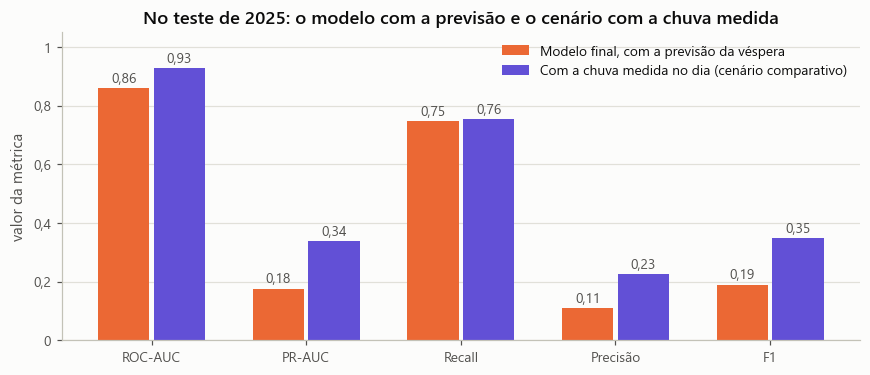

**Leitura.** Com a chuva medida, o PR-AUC do teste iria de 0,176 para 0,338. A diferença mostra que a incerteza da previsão da véspera pesa, pois ela tem baixa resolução e erra boa parte dos dias de chuva forte (seção 3.6). Mesmo com a chuva conhecida, o PR-AUC continua baixo, então a previsão não é o único limite: o registro do CGE e o que o modelo não vê também contam.

In [41]:
# 11.2 Gráfico: o que a previsão custa
metricas_medida_grafico = ["ROC-AUC", "PR-AUC", "Recall", "Precisão", "F1"]
x = np.arange(len(metricas_medida_grafico))
largura = 0.36
fig, ax = plt.subplots(figsize=(7.8, 3.3), constrained_layout=True)
b1 = ax.bar(x - largura / 2, quadro_final.loc[metricas_medida_grafico, "Teste 2025"], largura * 0.92, color=LARANJA, label="Modelo final, com a previsão da véspera")
b2 = ax.bar(x + largura / 2, quadro_final.loc[metricas_medida_grafico, "Teste 2025, com a chuva medida"], largura * 0.92, color="#6250d6", label="Com a chuva medida no dia (cenário comparativo)")
ax.bar_label(b1, labels=[virgula(f"{v:.2f}") for v in quadro_final.loc[metricas_medida_grafico, "Teste 2025"]], padding=2, fontsize=9, color="#52514e")
ax.bar_label(b2, labels=[virgula(f"{v:.2f}") for v in quadro_final.loc[metricas_medida_grafico, "Teste 2025, com a chuva medida"]], padding=2, fontsize=9, color="#52514e")
ax.set_xticks(x, metricas_medida_grafico)
ax.set_ylim(0, 1.05)
ax.set_ylabel("valor da métrica")
ax.set_title("No teste de 2025: o modelo com a previsão e o cenário com a chuva medida")
ax.xaxis.grid(False)
ax.legend(loc="upper right")
salvar(fig, "cenario_chuva_medida")
display(Markdown(virgula(f"**Leitura.** Com a chuva medida, o PR-AUC do teste iria de {quadro_final.loc['PR-AUC', 'Teste 2025']:.3f} para {quadro_final.loc['PR-AUC', 'Teste 2025, com a chuva medida']:.3f}. A diferença mostra que a incerteza da previsão da véspera pesa, pois ela tem baixa resolução e erra boa parte dos dias de chuva forte (seção 3.6). Mesmo com a chuva conhecida, o PR-AUC continua baixo, então a previsão não é o único limite: o registro do CGE e o que o modelo não vê também contam.")))

## 12. Quais variáveis pesam, quem o modelo enxerga pior e o que o alvo não mede

Primeiro, os coeficientes mostram o que o modelo aprendeu. Depois, o desempenho é aberto por região, porque o rótulo do CGE é desigual, e o alvo é comparado com versões mais próximas do uso do Elo.

,coeficiente (por desvio-padrão)
prev_chuva,1.444
prev_max_bloco,-0.283


,queda de PR-AUC ao embaralhar
Subprefeitura,0.089
Previsão do dia,0.128


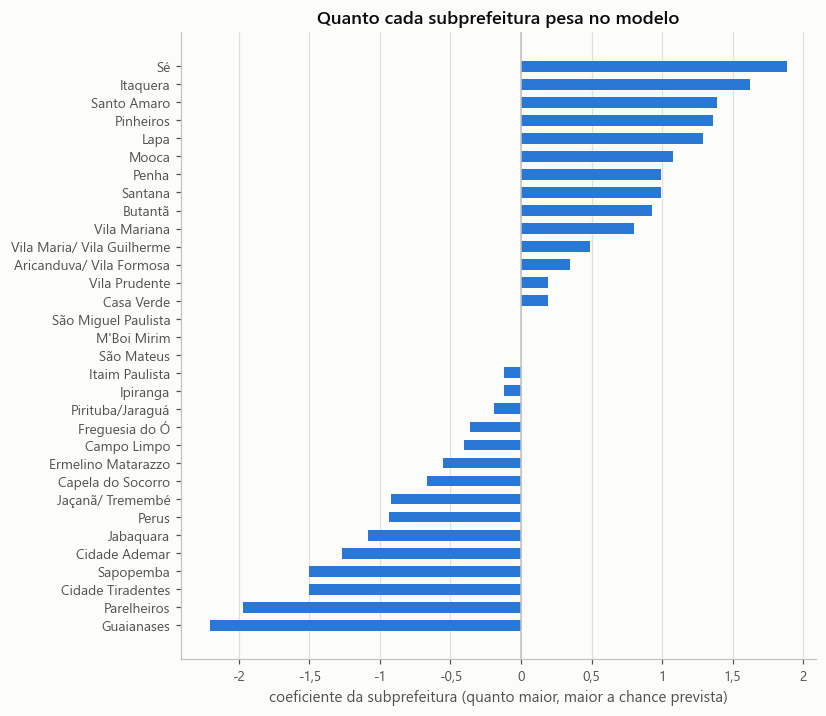

**Leitura.** O coeficiente da chuva prevista é positivo (1,44 por desvio-padrão de log da chuva): mais chuva prevista, mais chance. As medidas de chuva prevista são correlacionadas entre si, então o coeficiente de cada uma não deve ser lido sozinho. Embaralhar a subprefeitura derruba o PR-AUC em 0,089, e embaralhar a previsão, em 0,128. O maior coeficiente é o de Sé e o menor, o de Guaianases. Esses coeficientes refletem onde o CGE registrou alagamento em 2023 e 2024, o que mistura relevo, drenagem e presença de monitoramento.

In [42]:
# 12.1 O que o modelo aprendeu: coeficientes e importância por grupo de variáveis
nomes_coef = modelo.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(modelo.named_steps["clf"].coef_[0], index=nomes_coef)
coefs_previsao = coefs[[c for c in coefs.index if not c.startswith("subprefeitura_")]]
coefs_sub = coefs[[c for c in coefs.index if c.startswith("subprefeitura_")]]
coefs_sub.index = coefs_sub.index.str.replace("subprefeitura_", "", regex=False).map(subs.set_index("subprefeitura")["nome_exibicao"])
coefs_sub = coefs_sub.sort_values()
display(coefs_previsao.round(3).rename("coeficiente (por desvio-padrão)").to_frame())

# Embaralhar cada grupo no teste mostra quanto o PR-AUC depende dele.
grupos_variaveis = {"Previsão do dia": PREV_DIA, "Subprefeitura": LOCAL_ID}
gerador = np.random.default_rng(SEED)
pr_referencia = average_precision_score(y_teste, prob_teste)
quedas = {}
for nome, colunas in grupos_variaveis.items():
    valores = []
    for _ in range(10):
        embaralhado = X_teste.copy()
        embaralhado[colunas] = embaralhado[colunas].iloc[gerador.permutation(len(embaralhado))].reset_index(drop=True)
        valores.append(pr_referencia - average_precision_score(y_teste, modelo.predict_proba(embaralhado)[:, 1]))
    quedas[nome] = np.mean(valores)
importancia_grupos = pd.Series(quedas).sort_values()
display(importancia_grupos.round(3).rename("queda de PR-AUC ao embaralhar").to_frame())

fig, ax = plt.subplots(figsize=(7.4, 6.4), constrained_layout=True)
ax.barh(coefs_sub.index, coefs_sub.values, height=0.6, color=AZUL)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel("coeficiente da subprefeitura (quanto maior, maior a chance prevista)")
ax.set_title("Quanto cada subprefeitura pesa no modelo")
ax.yaxis.grid(False)
salvar(fig, "coeficientes_modelo")
display(Markdown(virgula(f"**Leitura.** O coeficiente da chuva prevista é positivo ({coefs_previsao.get('prev_chuva', float('nan')):.2f} por desvio-padrão de log da chuva): mais chuva prevista, mais chance. {'As medidas de chuva prevista são correlacionadas entre si, então o coeficiente de cada uma não deve ser lido sozinho. ' if len(PREV_DIA) > 1 else ''}Embaralhar a subprefeitura derruba o PR-AUC em {importancia_grupos['Subprefeitura']:.3f}, e embaralhar a previsão, em {importancia_grupos['Previsão do dia']:.3f}. O maior coeficiente é o de {coefs_sub.index[-1]} e o menor, o de {coefs_sub.index[0]}. Esses coeficientes refletem onde o CGE registrou alagamento em 2023 e 2024, o que mistura relevo, drenagem e presença de monitoramento.")))

In [43]:
# 12.2 Resultado por região e por subprefeitura no teste
teste_av = teste.assign(prob=prob_teste, nivel=nivel_atencao(prob_teste))
teste_av["atencao"] = teste_av["nivel"].isin(["médio", "alto"]).astype(int)

def resumo_grupo(g):
    pos = g["alagou"].sum()
    return pd.Series({
        "linhas": len(g), "alagamentos": int(pos), "% com alagamento": g["alagou"].mean() * 100,
        "% dos dias em atenção": g["atencao"].mean() * 100,
        "recall (médio ou alto)": g.loc[g["alagou"] == 1, "atencao"].mean() * 100 if pos else np.nan,
        "precisão (médio ou alto)": g.loc[g["atencao"] == 1, "alagou"].mean() * 100 if g["atencao"].sum() else np.nan,
    })

por_regiao = teste_av.groupby("regiao5").apply(resumo_grupo, include_groups=False).sort_values("alagamentos", ascending=False)
display(por_regiao.round(1))

por_sub_teste = teste_av.groupby("nome_exibicao").apply(resumo_grupo, include_groups=False).sort_values("alagamentos", ascending=True)
print("Subprefeituras com menos alagamentos registrados no teste:")
display(por_sub_teste.head(8).round(1))
print("Subprefeituras com mais alagamentos registrados no teste:")
display(por_sub_teste.tail(5).iloc[::-1].round(1))
print(f"Registros de alagamento em avenidas no treino e no teste: {cge['em_avenida'].mean():.0%}")

,linhas,alagamentos,% com alagamento,% dos dias em atenção,recall (médio ou alto),precisão (médio ou alto)
regiao5,,,,,,
Leste,4380.0,110.0,2.5,18.9,66.4,8.8
Norte,2555.0,70.0,2.7,16.8,62.9,10.3
Oeste,1095.0,69.0,6.3,36.9,85.5,14.6
Sul,3285.0,56.0,1.7,15.1,80.4,9.1
Centro,365.0,34.0,9.3,46.6,94.1,18.8


Subprefeituras com menos alagamentos registrados no teste:


,linhas,alagamentos,% com alagamento,% dos dias em atenção,recall (médio ou alto),precisão (médio ou alto)
nome_exibicao,,,,,,
Cidade Tiradentes,365.0,0.0,0.0,1.9,NaN,0.0
Jabaquara,365.0,0.0,0.0,4.7,NaN,0.0
Cidade Ademar,365.0,1.0,0.3,2.7,100.0,10.0
Capela do Socorro,365.0,1.0,0.3,14.2,100.0,1.9
Sapopemba,365.0,1.0,0.3,1.9,0.0,0.0
Perus,365.0,1.0,0.3,4.1,0.0,0.0
Ermelino Matarazzo,365.0,2.0,0.5,9.0,50.0,3.0
Parelheiros,365.0,2.0,0.5,0.5,0.0,0.0


Subprefeituras com mais alagamentos registrados no teste:


,linhas,alagamentos,% com alagamento,% dos dias em atenção,recall (médio ou alto),precisão (médio ou alto)
nome_exibicao,,,,,,
Sé,365.0,34.0,9.3,46.6,94.1,18.8
Lapa,365.0,26.0,7.1,38.6,84.6,15.6
Pinheiros,365.0,22.0,6.0,38.6,81.8,12.8
Itaquera,365.0,21.0,5.8,45.5,90.5,11.4
Butantã,365.0,21.0,5.8,33.4,90.5,15.6


Registros de alagamento em avenidas no treino e no teste: 54%


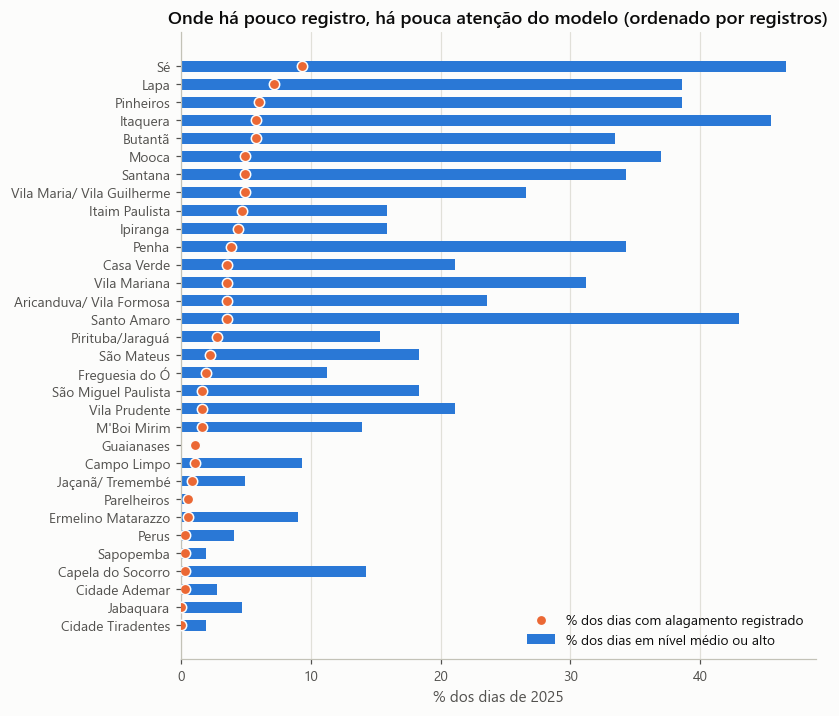

**Leitura.** A atenção do modelo acompanha o número de registros de cada subprefeitura (correlação de 0,88). A subprefeitura com menos dias em atenção não é necessariamente a que menos alaga: pode ser a que menos tem registro.

In [44]:
# 12.3 Gráfico do viés: registro desigual, e a atenção do modelo acompanha o registro
ordem_sub = por_sub_teste.sort_values("alagamentos")

fig, ax = plt.subplots(figsize=(7.4, 6.4), constrained_layout=True)
y_pos = np.arange(len(ordem_sub))
ax.barh(y_pos, ordem_sub["% dos dias em atenção"], height=0.6, color=AZUL, label="% dos dias em nível médio ou alto")
ax.scatter(ordem_sub["% com alagamento"], y_pos, s=46, color=LARANJA, edgecolor="#fcfcfb", linewidth=1, zorder=3, label="% dos dias com alagamento registrado")
ax.set_yticks(y_pos, ordem_sub.index)
ax.set_xlabel("% dos dias de 2025")
ax.set_title("Onde há pouco registro, há pouca atenção do modelo (ordenado por registros)")
ax.yaxis.grid(False)
ax.legend(loc="lower right")
salvar(fig, "vies_subprefeituras")
correlacao_vies = ordem_sub["alagamentos"].corr(ordem_sub["% dos dias em atenção"])
display(Markdown(virgula(f"**Leitura.** A atenção do modelo acompanha o número de registros de cada subprefeitura (correlação de {correlacao_vies:.2f}). A subprefeitura com menos dias em atenção não é necessariamente a que menos alaga: pode ser a que menos tem registro.")))

In [45]:
# 12.4 Se o modelo não souber o local? Comparação justa: as mesmas quantidades de dias em atenção em cada região.
# Sem o local, o modelo usa só a previsão e fica em atenção por uma parcela parecida dos dias em todas as regiões.
# Com o local, a atenção se concentra onde o CGE mais registra. Comparar o recall sem igualar o volume seria injusto.
oof_sem_local = np.full(len(treino), np.nan)
for tr, va in dobras:
    m = criar_logistica(PREV_DIA, [], **PARAMS).fit(treino[PREV_DIA].iloc[tr], y_treino[tr])
    oof_sem_local[va] = m.predict_proba(treino[PREV_DIA].iloc[va])[:, 1]
_, rec_sl, lim_sl = precision_recall_curve(y_treino[tem_oof], oof_sem_local[tem_oof])
limiar_sem_local = float(lim_sl[rec_sl[:-1] >= ALVO_RECALL_MEDIO].max())

atencao_sem_local = prob_ref >= limiar_sem_local
regiao_teste = teste["regiao5"].to_numpy()
regioes = list(por_regiao.index)

# O modelo com local é cortado, em cada região, para acionar a mesma quantidade de linhas que o modelo sem local acionou ali.
atencao_mesmo_volume = np.zeros(len(teste), dtype=bool)
for regiao in regioes:
    indices = np.flatnonzero(regiao_teste == regiao)
    k = int(round(atencao_sem_local[indices].mean() * len(indices)))
    atencao_mesmo_volume[indices[np.argsort(-prob_teste[indices], kind="stable")[:k]]] = True

rng = np.random.default_rng(SEED)
amostras = {r: [] for r in regioes}
for _ in range(1000):
    idx = reamostrar_dias(rng)
    for regiao in regioes:
        m = (regiao_teste[idx] == regiao) & (y_teste[idx] == 1)
        if m.sum():
            amostras[regiao].append((atencao_sem_local[idx][m].mean() * 100, atencao_mesmo_volume[idx][m].mean() * 100))

linhas = []
for regiao in regioes:
    m = (regiao_teste == regiao) & (y_teste == 1)
    a = np.array(amostras[regiao])
    linhas.append({"região": regiao, "alagamentos": int(m.sum()),
                   "% dos dias em atenção (nos dois)": atencao_sem_local[regiao_teste == regiao].mean() * 100,
                   "recall sem o local": atencao_sem_local[m].mean() * 100,
                   "IC95% inferior (sem)": np.percentile(a[:, 0], 2.5), "IC95% superior (sem)": np.percentile(a[:, 0], 97.5),
                   "recall com o local": atencao_mesmo_volume[m].mean() * 100,
                   "IC95% inferior (com)": np.percentile(a[:, 1], 2.5), "IC95% superior (com)": np.percentile(a[:, 1], 97.5)})
comparacao_local = pd.DataFrame(linhas).set_index("região")
display(comparacao_local.round(1))
print(virgula(f"PR-AUC no teste: com o local {average_precision_score(y_teste, prob_teste):.3f} | sem o local {average_precision_score(y_teste, prob_ref):.3f}"))
com_local, sem_local_rc = comparacao_local["recall com o local"], comparacao_local["recall sem o local"]
regioes_com = [r for r in regioes if com_local[r] > sem_local_rc[r]]
regioes_sem = [r for r in regioes if com_local[r] < sem_local_rc[r]]
regioes_igual = [r for r in regioes if com_local[r] == sem_local_rc[r]]
sobrepoem = all(comparacao_local.loc[r, "IC95% inferior (com)"] <= comparacao_local.loc[r, "IC95% superior (sem)"]
                and comparacao_local.loc[r, "IC95% inferior (sem)"] <= comparacao_local.loc[r, "IC95% superior (com)"] for r in regioes)
frase_ic = "Os intervalos de confiança se sobrepõem em todas as regiões, então essas diferenças não podem ser afirmadas" if sobrepoem else "Em parte das regiões os intervalos não se sobrepõem"
pct_atencao = por_regiao["% dos dias em atenção"]
display(Markdown(virgula(f"**Leitura.** Com o mesmo volume de dias em atenção em cada região, o modelo que sabe o local cobre mais alagamentos em {', '.join(regioes_com) or 'nenhuma região'}, menos em {', '.join(regioes_sem) or 'nenhuma região'} e o mesmo em {', '.join(regioes_igual) or 'nenhuma região'}. {frase_ic}, principalmente onde há poucos casos (o Centro, que é só a Sé, tem {comparacao_local.loc['Centro', 'alagamentos']:.0f} alagamentos). O que muda de fato é onde a atenção fica: com o local, ela vai de {pct_atencao.min():.0f}% dos dias na região {pct_atencao.idxmin()} a {pct_atencao.max():.0f}% no {pct_atencao.idxmax()}. Sem o local, fica entre {100 * pd.Series(atencao_sem_local).groupby(regiao_teste).mean().min():.0f}% e {100 * pd.Series(atencao_sem_local).groupby(regiao_teste).mean().max():.0f}%. Saber o local melhora o PR-AUC geral (de {average_precision_score(y_teste, prob_ref):.3f} para {average_precision_score(y_teste, prob_teste):.3f}), mas concentra a atenção onde o CGE já registra. Essa troca é uma escolha do produto, e deve ser discutida com quem mora nas regiões com poucos registros.")))

,alagamentos,% dos dias em atenção (nos dois),recall sem o local,IC95% inferior (sem),IC95% superior (sem),recall com o local,IC95% inferior (com),IC95% superior (com)
região,,,,,,,,
Leste,110,24.1,70.9,54.5,85.3,78.2,69.0,87.4
Norte,70,23.7,68.6,50.8,86.3,78.6,64.0,90.6
Oeste,69,24.1,72.5,57.7,86.6,71.0,56.1,85.2
Sul,56,25.9,83.9,70.2,94.0,85.7,73.3,94.6
Centro,34,24.1,70.6,54.3,85.3,70.6,54.3,85.3


PR-AUC no teste: com o local 0,176 | sem o local 0,112


**Leitura.** Com o mesmo volume de dias em atenção em cada região, o modelo que sabe o local cobre mais alagamentos em Leste, Norte, Sul, menos em Oeste e o mesmo em Centro. Os intervalos de confiança se sobrepõem em todas as regiões, então essas diferenças não podem ser afirmadas, principalmente onde há poucos casos (o Centro, que é só a Sé, tem 34 alagamentos). O que muda de fato é onde a atenção fica: com o local, ela vai de 15% dos dias na região Sul a 47% no Centro. Sem o local, fica entre 24% e 26%. Saber o local melhora o PR-AUC geral (de 0,112 para 0,176), mas concentra a atenção onde o CGE já registra. Essa troca é uma escolha do produto, e deve ser discutida com quem mora nas regiões com poucos registros.

In [46]:
# 12.5 Onde o CGE registrou pouco, o modelo quase não avisa
casos_no_treino = treino.groupby("subprefeitura")["alagou"].sum()
faixa_registros = pd.cut(teste["subprefeitura"].map(casos_no_treino), [-1, 15, 40, np.inf], labels=["até 15 casos no treino", "de 16 a 40", "mais de 40"])
atencao_final = nivel_atencao(prob_teste) != "baixo"
alto_final = nivel_atencao(prob_teste) == "alto"
# Uma opção a discutir: um piso de atenção. Se a previsão sozinha, sem o local, já indicaria atenção, a subprefeitura sobe ao menos para médio.
atencao_com_piso = atencao_final | atencao_sem_local

linhas = []
for faixa in faixa_registros.cat.categories:
    m = (faixa_registros == faixa).to_numpy()
    casos = m & (y_teste == 1)
    n_sub = teste.loc[m, "subprefeitura"].nunique()
    linhas.append({"faixa": faixa, "subprefeituras": n_sub, "alagamentos em 2025": int(casos.sum()),
                   "% cobertos em médio ou alto": atencao_final[casos].mean() * 100, "% cobertos em alto": alto_final[casos].mean() * 100,
                   "dias em atenção por subprefeitura": atencao_final[m].sum() / n_sub, "precisão em atenção (%)": y_teste[m & atencao_final].mean() * 100,
                   "% cobertos com o piso": atencao_com_piso[casos].mean() * 100, "dias em atenção com o piso": atencao_com_piso[m].sum() / n_sub,
                   "precisão com o piso (%)": y_teste[m & atencao_com_piso].mean() * 100})
tabela_registros = pd.DataFrame(linhas).set_index("faixa")
display(tabela_registros.round(1))

por_sub_niveis = teste_av.assign(alto=alto_final).groupby("nome_exibicao").agg(alagamentos=("alagou", "sum"), dias_atencao=("atencao", "sum"), dias_alto=("alto", "sum"))
sem_atencao = por_sub_niveis[por_sub_niveis["dias_atencao"] == 0]
sem_alto = por_sub_niveis[por_sub_niveis["dias_alto"] == 0]
faixa_baixa, faixa_alta = tabela_registros.iloc[0], tabela_registros.iloc[-1]
display(Markdown(virgula(f"**Leitura.** Onde o CGE registrou pouco no treino, o modelo quase não avisa. Nas subprefeituras com até 15 casos no treino, o nível alto cobre {faixa_baixa['% cobertos em alto']:.0f}% dos alagamentos registrados em 2025, contra {faixa_alta['% cobertos em alto']:.0f}% nas que tiveram mais de 40. Em {len(sem_alto)} das 32 subprefeituras, o nível alto nunca apareceu em 2025, e elas somam {int(sem_alto['alagamentos'].sum())} dias-subprefeitura com alagamento. Em {', '.join(sem_atencao.index) or 'nenhuma'}, nenhum dia entrou em atenção, apesar de {int(sem_atencao['alagamentos'].sum())} alagamentos registrados. Isso não é economia de chamadas: é o modelo repetindo a falta de registro. **Uma opção a discutir com a comunidade** é um piso de atenção: quando a previsão sozinha já indicasse atenção, a subprefeitura subiria ao menos para médio. Nessas subprefeituras, a cobertura iria de {faixa_baixa['% cobertos em médio ou alto']:.0f}% para {faixa_baixa['% cobertos com o piso']:.0f}%, os dias em atenção de {faixa_baixa['dias em atenção por subprefeitura']:.0f} para {faixa_baixa['dias em atenção com o piso']:.0f}, e a precisão cairia de {faixa_baixa['precisão em atenção (%)']:.1f}% para {faixa_baixa['precisão com o piso (%)']:.1f}%. O piso não foi adotado neste modelo, porque seria uma mudança feita depois de ver o teste.")))

,subprefeituras,alagamentos em 2025,% cobertos em médio ou alto,% cobertos em alto,dias em atenção por subprefeitura,precisão em atenção (%),% cobertos com o piso,dias em atenção com o piso,precisão com o piso (%)
faixa,,,,,,,,,
até 15 casos no treino,16,75,48.0,14.7,28.7,7.8,77.3,90.9,4.0
de 16 a 40,8,98,72.4,29.6,88.4,10.0,76.5,96.6,9.7
mais de 40,8,166,88.0,60.8,145.0,12.6,88.0,145.0,12.6


**Leitura.** Onde o CGE registrou pouco no treino, o modelo quase não avisa. Nas subprefeituras com até 15 casos no treino, o nível alto cobre 15% dos alagamentos registrados em 2025, contra 61% nas que tiveram mais de 40. Em 8 das 32 subprefeituras, o nível alto nunca apareceu em 2025, e elas somam 13 dias-subprefeitura com alagamento. Em Guaianases, nenhum dia entrou em atenção, apesar de 4 alagamentos registrados. Isso não é economia de chamadas: é o modelo repetindo a falta de registro. **Uma opção a discutir com a comunidade** é um piso de atenção: quando a previsão sozinha já indicasse atenção, a subprefeitura subiria ao menos para médio. Nessas subprefeituras, a cobertura iria de 48% para 77%, os dias em atenção de 29 para 91, e a precisão cairia de 7,8% para 4,0%. O piso não foi adotado neste modelo, porque seria uma mudança feita depois de ver o teste.

In [47]:
# 12.6 O alvo representa o uso do Elo? O mesmo modelo avaliado contra versões mais próximas do uso.
alvos_alternativos = {"Qualquer ponto (alvo do modelo)": "alagou", "Ponto de 60 minutos ou mais": "alagou_longo",
                      "Ponto intransitável": "alagou_intransitavel", "Ponto fora de avenida": "alagou_fora_avenida",
                      "Ponto iniciado às 8h ou depois": "alagou_depois_8h"}
# Casos em que todos os pontos começaram antes das 8h: já tinham começado na hora da decisão.
so_antes_8h = ((teste["alagou"] == 1) & (teste["alagou_depois_8h"] == 0)).to_numpy()
niveis_previstos = nivel_atencao(prob_teste)
linhas = []
for nome, coluna in alvos_alternativos.items():
    # No recorte das 8h, os casos que já tinham começado saem da conta: não são acerto nem erro.
    usar = ~so_antes_8h if coluna == "alagou_depois_8h" else np.ones(len(teste), dtype=bool)
    y_alvo, p_alvo, niveis_alvo = teste[coluna].to_numpy()[usar], prob_teste[usar], niveis_previstos[usar]
    linhas.append({"alvo": nome, "casos em 2025": int(y_alvo.sum()), "prevalência (%)": y_alvo.mean() * 100,
                   "PR-AUC": average_precision_score(y_alvo, p_alvo), "ROC-AUC": roc_auc_score(y_alvo, p_alvo),
                   "% dos casos em médio ou alto": (niveis_alvo[y_alvo == 1] != "baixo").mean() * 100,
                   "% dos casos em alto": (niveis_alvo[y_alvo == 1] == "alto").mean() * 100})
tabela_alvos = pd.DataFrame(linhas).set_index("alvo")
display(tabela_alvos.round(3))
display(Markdown(virgula(f"**Leitura.** O alvo do modelo mede qualquer ponto registrado pelo CGE, mas o Elo foi pensado para água que sobe aos poucos em rua residencial. Avaliado contra pontos mais próximos desse uso, o modelo cobre em médio ou alto {tabela_alvos.loc['Ponto de 60 minutos ou mais', '% dos casos em médio ou alto']:.0f}% dos pontos de 60 minutos ou mais, {tabela_alvos.loc['Ponto intransitável', '% dos casos em médio ou alto']:.0f}% dos pontos intransitáveis e {tabela_alvos.loc['Ponto fora de avenida', '% dos casos em médio ou alto']:.0f}% dos pontos fora de avenida. Esses recortes ainda são registros do CGE, em vias que ele monitora: não mostram o que acontece nas ruas sem monitoramento. A decisão é tomada de manhã, e em {int(so_antes_8h.sum())} dos {int(y_teste.sum())} casos de 2025 ({so_antes_8h.sum() / y_teste.sum():.0%}) todos os pontos já tinham começado antes das 8h. Sem esses casos, o PR-AUC é {tabela_alvos.loc['Ponto iniciado às 8h ou depois', 'PR-AUC']:.3f}, e o nível alto cobre {tabela_alvos.loc['Ponto iniciado às 8h ou depois', '% dos casos em alto']:.0f}% dos alagamentos.")))

,casos em 2025,prevalência (%),PR-AUC,ROC-AUC,% dos casos em médio ou alto,% dos casos em alto
alvo,,,,,,
Qualquer ponto (alvo do modelo),339,2.902,0.176,0.860,74.631,41.593
Ponto de 60 minutos ou mais,224,1.918,0.134,0.867,75.893,43.750
Ponto intransitável,212,1.815,0.120,0.857,74.528,43.868
Ponto fora de avenida,194,1.661,0.113,0.862,77.320,42.784
Ponto iniciado às 8h ou depois,270,2.325,0.162,0.865,75.556,44.815


**Leitura.** O alvo do modelo mede qualquer ponto registrado pelo CGE, mas o Elo foi pensado para água que sobe aos poucos em rua residencial. Avaliado contra pontos mais próximos desse uso, o modelo cobre em médio ou alto 76% dos pontos de 60 minutos ou mais, 75% dos pontos intransitáveis e 77% dos pontos fora de avenida. Esses recortes ainda são registros do CGE, em vias que ele monitora: não mostram o que acontece nas ruas sem monitoramento. A decisão é tomada de manhã, e em 69 dos 339 casos de 2025 (20%) todos os pontos já tinham começado antes das 8h. Sem esses casos, o PR-AUC é 0,162, e o nível alto cobre 45% dos alagamentos.

In [48]:
# 12.7 Dentro do mesmo dia, o modelo muda a ordem das subprefeituras?
subs_por_ponto = prev.groupby(["grid_lat", "grid_lon"])["subprefeitura"].nunique().sort_values(ascending=False)
lista_fixa = teste["subprefeitura"].map(freq_sub).to_numpy()
correlacoes_dia, pares_dia, auc_modelo_dia, auc_lista_dia = [], [], [], []
for indices in linhas_do_dia:
    correlacao_dia = pd.Series(prob_teste[indices]).rank().corr(pd.Series(lista_fixa[indices]).rank())
    if not np.isnan(correlacao_dia):
        correlacoes_dia.append(correlacao_dia)
    y_dia = y_teste[indices]
    if 0 < y_dia.sum() < len(y_dia):
        pares_dia.append(y_dia.sum() * (len(y_dia) - y_dia.sum()))
        auc_modelo_dia.append(roc_auc_score(y_dia, prob_teste[indices]))
        auc_lista_dia.append(roc_auc_score(y_dia, lista_fixa[indices]))
correlacao_media_dia = float(np.mean(correlacoes_dia))
auc_dentro_dia_modelo = float(np.average(auc_modelo_dia, weights=pares_dia))
auc_dentro_dia_lista = float(np.average(auc_lista_dia, weights=pares_dia))
display(Markdown(virgula(f"**Leitura.** Das 32 subprefeituras, {subs_por_ponto.iloc[0]} recebem exatamente a mesma previsão, porque a JMA cobre a cidade com só {len(subs_por_ponto)} pontos. Dentro de um mesmo dia, a ordem dada pelo modelo às subprefeituras tem correlação média de {correlacao_media_dia:.2f} com uma lista fixa, a da frequência histórica. Para separar, dentro do dia, quais subprefeituras tiveram registro, o AUC é de {auc_dentro_dia_modelo:.3f} para o modelo e {auc_dentro_dia_lista:.3f} para a lista. Portanto, o modelo responde sobretudo **em que dia** abrir a chamada. Dentro do dia, ele repete onde o CGE costuma registrar. Para dizer qual subprefeitura será atingida naquele dia, seria preciso uma previsão de maior resolução.")))

**Leitura.** Das 32 subprefeituras, 27 recebem exatamente a mesma previsão, porque a JMA cobre a cidade com só 3 pontos. Dentro de um mesmo dia, a ordem dada pelo modelo às subprefeituras tem correlação média de 0,97 com uma lista fixa, a da frequência histórica. Para separar, dentro do dia, quais subprefeituras tiveram registro, o AUC é de 0,761 para o modelo e 0,769 para a lista. Portanto, o modelo responde sobretudo **em que dia** abrir a chamada. Dentro do dia, ele repete onde o CGE costuma registrar. Para dizer qual subprefeitura será atingida naquele dia, seria preciso uma previsão de maior resolução.

In [49]:
# 12.8 Estudo de caso: Jardim Pantanal (subprefeitura de São Miguel), início de fevereiro de 2025.
# A Agência Pública relata moradores ilhados a partir da madrugada de 01/02/2025 (fonte citada no escopo).
teste_av["nivel_medida"] = np.select([prob_medida_teste >= limiar_alto_medida, prob_medida_teste >= limiar_medio_medida], ["alto", "médio"], default="baixo")
caso = teste_av[(teste_av["subprefeitura"] == "SAO MIGUEL") & teste_av["data"].between("2025-01-30", "2025-02-08")]
tabela_caso = caso[["data", "prev_chuva", "inmet_chuva_A701", "n_pontos", "nivel", "nivel_medida"]].copy()
tabela_caso["data"] = tabela_caso["data"].dt.strftime("%d/%m/%Y")
tabela_caso = tabela_caso.rename(columns={"prev_chuva": "chuva prevista (mm)", "inmet_chuva_A701": "chuva INMET Mirante (mm)",
                                          "n_pontos": "pontos CGE", "nivel": "nível (previsão da véspera)", "nivel_medida": "nível (com a chuva medida)"})
display(tabela_caso.round(1))

dias_caso = caso[caso["alagou"] == 1]
n_dias_caso = len(dias_caso)
n_previsao = int((dias_caso["nivel"] != "baixo").sum())
n_alto = int((dias_caso["nivel"] == "alto").sum())
n_medida = int((dias_caso["nivel_medida"] != "baixo").sum())
display(Markdown(f'''
**Leitura do caso.** O CGE registrou pontos em São Miguel em {n_dias_caso} dias desse período. Com a previsão da véspera, o modelo ficou em nível médio ou alto em {n_previsao} desses {n_dias_caso} dias, dos quais {n_alto} em alto. Com a chuva medida, em {n_medida} de {n_dias_caso}. Nos dias de 02 a 04/02/2025 há 27 registros com asterisco e horário idêntico, o que sugere registro administrativo de uma ocorrência longa. O CGE não explica o símbolo, então os registros foram mantidos como estão.
'''))

,data,chuva prevista (mm),chuva INMET Mirante (mm),pontos CGE,nível (previsão da véspera),nível (com a chuva medida)
9519,30/01/2025,25.6,7.4,0,alto,baixo
9520,31/01/2025,4.8,23.6,1,médio,alto
9521,01/02/2025,3.6,63.6,9,baixo,médio
9522,02/02/2025,19.2,13.2,9,alto,médio
9523,03/02/2025,1.4,32.6,10,baixo,baixo
9524,04/02/2025,2.2,13.0,9,baixo,baixo
9525,05/02/2025,5.4,0.0,0,médio,baixo
9526,06/02/2025,0.0,18.6,0,baixo,baixo
9527,07/02/2025,4.2,0.0,0,baixo,baixo
9528,08/02/2025,0.0,0.0,0,baixo,baixo



**Leitura do caso.** O CGE registrou pontos em São Miguel em 5 dias desse período. Com a previsão da véspera, o modelo ficou em nível médio ou alto em 2 desses 5 dias, dos quais 1 em alto. Com a chuva medida, em 3 de 5. Nos dias de 02 a 04/02/2025 há 27 registros com asterisco e horário idêntico, o que sugere registro administrativo de uma ocorrência longa. O CGE não explica o símbolo, então os registros foram mantidos como estão.


**O que isso significa.** O rótulo mede **o que o CGE registrou**, não o que aconteceu em toda rua da cidade. Mais da metade dos pontos está em avenidas, boa parte dura menos de uma hora e parte das subprefeituras periféricas tem pouquíssimos registros, enquanto o Elo foi pensado para água que sobe aos poucos em rua residencial. Um nível baixo em uma subprefeitura periférica pode significar que ali quase nunca houve observação, e não que ali quase nunca alague.

Que parte dessa desigualdade vem do relevo e da drenagem e que parte vem de onde o CGE observa é uma hipótese: sem uma fonte independente, como os chamados do SP156, não dá para medir. O que a seção 12 mede é como o desempenho varia entre regiões. Saber o local ajuda o modelo, mas repete o padrão de registro. Essa é uma escolha do produto, e não só técnica.

## 13. Conclusão e leitura para o cidadão

In [50]:
# 13.1 Conclusão gerada a partir dos números calculados
total_alag = int(y_teste.sum())
cobertura_atencao = 100 - perdidos_teste
dias_por_sub = pd.Series(nivel_atencao(prob_teste) != "baixo").groupby(teste["nome_exibicao"]).sum()
taxa_alto = niveis_teste.loc["alto", "% com alagamento registrado"]
taxa_medio = niveis_teste.loc["médio", "% com alagamento registrado"]
taxa_baixo = niveis_teste.loc["baixo", "% com alagamento registrado"]
precisao_atencao = lado_a_lado.loc["Precisão", "Teste (2025)"]
falsos_alto = 100 - taxa_alto
cobertura_medida = recall_score(y_teste, (prob_medida_teste >= limiar_medio_medida).astype(int)) * 100

conclusao = f'''
**Para quem coordena o bairro, em linguagem simples:**

1. **Quando vale abrir a chamada.** De cada 100 alagamentos registrados em 2025, o nível alto, que é o que abre a chamada, teria sido acionado em {cobertura_alto:.0f}. De cada 100 chamadas abertas, {taxa_alto:.0f} coincidiram com alagamento registrado naquele dia e subprefeitura, e {falsos_alto:.0f} teriam sido à toa.
2. **Quando vale se preparar.** Os níveis médio e alto, que avisam as lideranças, cobriram {cobertura_atencao:.0f} de cada 100 alagamentos, abaixo do alvo de 80 definido no treino. Em {(1 - precisao_atencao) * 100:.0f} de cada 100 desses dias, não houve registro de alagamento.
3. **Quanto isso custa.** Uma subprefeitura ficaria, em média, cerca de {dias_atencao:.0f} dias de 2025 em nível médio ou alto, dos quais {dias_alto:.0f} em alto. Por isso existem dois níveis: o médio só prepara, e só o alto abre a chamada.
4. **Onde o modelo quase não avisa.** Nas subprefeituras em que o CGE registrou pouco, o nível alto cobriu só {faixa_baixa['% cobertos em alto']:.0f} de cada 100 alagamentos, contra {faixa_alta['% cobertos em alto']:.0f} onde registrou mais. Em {len(sem_alto)} das 32 subprefeituras, o nível alto nunca apareceu. Em {', '.join(sem_atencao.index) or 'nenhuma'}, nenhum dia entrou em atenção, mesmo com {int(sem_atencao['alagamentos'].sum())} alagamentos registrados. Quem mora nesses lugares não deve tratar um nível baixo como garantia, e um piso de atenção precisa ser discutido com a comunidade.
5. **Ele responde sobretudo em que dia.** Quase toda a cidade recebe a mesma previsão, então, dentro de um mesmo dia, o modelo repete quase a mesma ordem de subprefeituras. Ele não sabe dizer qual subprefeitura será atingida naquele dia.
6. **Nível baixo não quer dizer seguro.** {perdidos_teste:.0f} de cada 100 alagamentos registrados caíram em dia classificado como baixo. Se a água está subindo, vale o que a rua está vendo e o aviso oficial.
7. **A qualidade da previsão pesa, mas não é o único limite.** Com a chuva do dia conhecida, os níveis médio e alto cobririam {cobertura_medida:.0f} de cada 100 alagamentos, com menos dias em atenção ({dias_atencao_medida:.0f} em vez de {dias_atencao:.0f}), e ainda assim a maioria dos dias em atenção não teria registro.
8. **O que ele não faz.** Não emite alerta, não aponta rua e não diz se há perigo. Ele só ajuda a decidir quando abrir a chamada, que é a parte do Elo que descobre quais ruas ficaram em silêncio.

**O que ainda precisa ser confirmado.** A ideia de que abrir a chamada demais cansa quem é voluntário é uma hipótese, e ainda precisa ser conferida em conversa com uma liderança.
'''
display(Markdown(virgula(conclusao)))


**Para quem coordena o bairro, em linguagem simples:**

1. **Quando vale abrir a chamada.** De cada 100 alagamentos registrados em 2025, o nível alto, que é o que abre a chamada, teria sido acionado em 42. De cada 100 chamadas abertas, 19 coincidiram com alagamento registrado naquele dia e subprefeitura, e 81 teriam sido à toa.
2. **Quando vale se preparar.** Os níveis médio e alto, que avisam as lideranças, cobriram 75 de cada 100 alagamentos, abaixo do alvo de 80 definido no treino. Em 89 de cada 100 desses dias, não houve registro de alagamento.
3. **Quanto isso custa.** Uma subprefeitura ficaria, em média, cerca de 73 dias de 2025 em nível médio ou alto, dos quais 23 em alto. Por isso existem dois níveis: o médio só prepara, e só o alto abre a chamada.
4. **Onde o modelo quase não avisa.** Nas subprefeituras em que o CGE registrou pouco, o nível alto cobriu só 15 de cada 100 alagamentos, contra 61 onde registrou mais. Em 8 das 32 subprefeituras, o nível alto nunca apareceu. Em Guaianases, nenhum dia entrou em atenção, mesmo com 4 alagamentos registrados. Quem mora nesses lugares não deve tratar um nível baixo como garantia, e um piso de atenção precisa ser discutido com a comunidade.
5. **Ele responde sobretudo em que dia.** Quase toda a cidade recebe a mesma previsão, então, dentro de um mesmo dia, o modelo repete quase a mesma ordem de subprefeituras. Ele não sabe dizer qual subprefeitura será atingida naquele dia.
6. **Nível baixo não quer dizer seguro.** 25 de cada 100 alagamentos registrados caíram em dia classificado como baixo. Se a água está subindo, vale o que a rua está vendo e o aviso oficial.
7. **A qualidade da previsão pesa, mas não é o único limite.** Com a chuva do dia conhecida, os níveis médio e alto cobririam 76 de cada 100 alagamentos, com menos dias em atenção (35 em vez de 73), e ainda assim a maioria dos dias em atenção não teria registro.
8. **O que ele não faz.** Não emite alerta, não aponta rua e não diz se há perigo. Ele só ajuda a decidir quando abrir a chamada, que é a parte do Elo que descobre quais ruas ficaram em silêncio.

**O que ainda precisa ser confirmado.** A ideia de que abrir a chamada demais cansa quem é voluntário é uma hipótese, e ainda precisa ser conferida em conversa com uma liderança.


In [51]:
# 13.2 Registro de todos os números usados no relatório, para o relatório e o notebook não divergirem
resultados = {
    "dados": {"linhas_base": int(len(base)), "registros_cge": int(len(cge)), "duplicatas_removidas": duplicadas,
              "dias_periodo": int(len(periodo)), "dias_com_alagamento_por_ano": {int(k): int(v) for k, v in dias_ano.items()},
              "prevalencia": float(base["alagou"].mean()), "pct_em_avenida": float(cge["em_avenida"].mean()),
              "pct_pontos_menos_de_1h": float(pct_curtos), "pct_pontos_antes_8h": float(pct_antes_8h),
              "pontos_grade_previsao": int(n_grade_prev), "coerencia_fontes": coerencia.round(4).to_dict(orient="records")},
    "split": {"treino": resumo_conjunto(treino), "teste": resumo_conjunto(teste)},
    "comparacao_modelos": comparacao_modelos.round(6).to_dict(),
    "comparacao_modelos_final": comparacao_modelos_final.round(6).to_dict(),
    "configs_finais": {k: {a.replace("clf__", ""): (list(b) if isinstance(b, tuple) else b) for a, b in v.items()} for k, v in configs_finais.items()},
    "melhores_configs": {k: {a.replace("clf__", ""): (list(b) if isinstance(b, tuple) else b) for a, b in v.items()} for k, v in melhores_configs.items()},
    "familia_escolhida": familia_final,
    "comparacao_conjuntos": comparacao_conjuntos.round(6).to_dict(),
    "conjunto_final": conjunto_final,
    "busca": {"combinacoes": n_combinacoes, "hiperparametros": list(GRADE), "dobras": N_DOBRAS, "ajustes": n_combinacoes * N_DOBRAS,
              "escolhida": PARAMS, "n_variaveis": len(VARIAVEIS), "variaveis": VARIAVEIS,
              "pr_auc_treino_cv": float(pr_treino_cv), "pr_auc_validacao_cv": float(pr_validacao_cv),
              "melhor_pr_auc_validacao": float(melhor["PR-AUC validação"]), "melhor_C": float(melhor["C"]),
              "melhor_penalizacao": melhor["penalização"], "melhor_class_weight": melhor["class_weight"],
              "equivalentes": int(len(candidatas)), "positivos_dobras": [int(v) for v in positivos_dobras],
              "diferenca_para_melhor": float(escolhida["diferença para a melhor"]), "erro_padrao_diferenca": float(escolhida["erro-padrão da diferença"])},
    "limiares": {"medio": LIMIAR_MEDIO, "alto": LIMIAR_ALTO},
    "compromisso": tabela_compromisso.round(4).to_dict(),
    "metricas_medio": lado_a_lado.round(6).to_dict(), "metricas_alto": lado_a_lado_alto.round(6).to_dict(),
    "overfitting": {"queda_cv": float(queda_cv), "classe_cv": classe_overfitting(queda_cv), "queda_teste": float(queda_teste), "classe_teste": classe_overfitting(queda_teste),
                    "lift_treino": float(lift_treino), "lift_oof": float(lift_oof), "lift_teste": float(lift_teste)},
    "referencias_teste": tabela_referencias.round(6).to_dict(),
    "dias_com_chuva": quadro_chuva.round(6).to_dict(),
    "probabilidade_media": {"prevista_teste": float(prob_teste.mean()), "real_teste": float(y_teste.mean())},
    "niveis": {"teste": niveis_teste.round(4).to_dict(), "validacao": niveis_treino.round(4).to_dict()},
    "chuva_medida": {"limiar_medio": limiar_medio_medida, "limiar_alto": limiar_alto_medida, "recall_alto": float(recall_alto_medida), "recall_alto_final": float(recall_alto), "dias_atencao": float(dias_atencao_medida), "cobertura_atencao_pct": float(cobertura_medida)},
    "quadro_final": quadro_final.round(6).to_dict(),
    "coeficientes_previsao": coefs_previsao.round(4).to_dict(),
    "importancia_grupos": importancia_grupos.round(6).to_dict(),
    "por_regiao": por_regiao.round(4).to_dict(),
    "correlacao_vies": float(correlacao_vies),
    "sem_local": {"pr_auc": float(average_precision_score(y_teste, prob_ref)), "roc_auc": float(roc_auc_score(y_teste, prob_ref)), "tabela": comparacao_local.round(4).to_dict()},
    "alvos_alternativos": tabela_alvos.round(4).to_dict(),
    "sensibilidade_margem": sensibilidade_teste.round(6).reset_index().to_dict(orient="records"),
    "medidas_previsao": comparacao_medidas.round(6).to_dict(), "medida_escolhida": medida_escolhida, "prev_dia": PREV_DIA,
    "cauda_alta": {"casos": int(cauda_alta.sum()), "prevista": float(prob_teste[cauda_alta].mean()), "real": float(y_teste[cauda_alta].mean())},
    "registros": tabela_registros.round(4).to_dict(), "sem_alto": {"subprefeituras": int(len(sem_alto)), "casos": int(sem_alto["alagamentos"].sum())},
    "sem_atencao": {"nomes": list(sem_atencao.index), "casos": int(sem_atencao["alagamentos"].sum())},
    "dentro_do_dia": {"correlacao_media": correlacao_media_dia, "auc_modelo": auc_dentro_dia_modelo, "auc_lista": auc_dentro_dia_lista, "subs_mesma_previsao": int(subs_por_ponto.iloc[0])},
    "antes_8h": {"casos": int(so_antes_8h.sum()), "pct": float(so_antes_8h.sum() / y_teste.sum())},
    "caso_jardim_pantanal": {"dias_com_registro": n_dias_caso, "medio_ou_alto_previsao": n_previsao, "alto_previsao": n_alto, "medio_ou_alto_medida": n_medida},
    "cidadao": {"dias_atencao_por_sub": float(dias_atencao), "dias_alto_por_sub": float(dias_alto), "cobertura_atencao_pct": float(cobertura_atencao),
                "cobertura_alto_pct": float(cobertura_alto), "taxa_alto_pct": float(taxa_alto),
                "dias_atencao_min": {"subprefeitura": dias_por_sub.idxmin(), "dias": int(dias_por_sub.min())},
                "dias_atencao_max": {"subprefeitura": dias_por_sub.idxmax(), "dias": int(dias_por_sub.max())}},
    "versoes": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                "scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__},
}
(RESULTADOS / "metricas.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Resultados registrados em resultados/metricas.json")

Resultados registrados em resultados/metricas.json
